# Task 2: Efficient Attention and Context Memory

Name: Muhammad Danish Zaheer Awan | REG id: 25280092

Part A compares exact attention implementations. Part B trains all 42 required
MQAR runs and preserves final checkpoints. Part C compares six cache policies on
the same 180 staff retrieval prompts, including actual packed-cache system costs.
Colab computes and resumes; local **ATML** Run All strictly replays saved evidence.
The eight main figures use **Times New Roman, 10 pt** from the first cloud run.
See `README.md` for methods, limitations, recovery and reproduction instructions.


## Common setup

Upload this complete `Task_2/` folder to `MyDrive/ATML_PA4/PA_4/`. Raw model files download into runtime `Data/Task_2/`; supplied small benchmark assets are bundled.


In [1]:
# Name : Muhammad Danish Zaheer Awan
# REG id : 25280092
from importlib.util import find_spec
from pathlib import Path
import sys
try:
    IN_COLAB = find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
RUN_MODE = "compute" if IN_COLAB else "replay"
DRIVE_PROJECT = "ATML_PA4/PA_4"
print(f"Task_2 | mode={RUN_MODE} | Colab={IN_COLAB}")


Task_2 | mode=replay | Colab=False


### Drive and local working storage

Frequent reads run on `/content/ATML_PA4/PA_4/`. Results are backed up to Drive throughout the run. Copying code preserves the existing Drive results.


In [2]:
import shutil
if RUN_MODE == "compute":
    from google.colab import drive
    drive.mount("/content/drive")
    drive_root = Path("/content/drive/MyDrive") / DRIVE_PROJECT
    PROJECT_ROOT = Path("/content") / DRIVE_PROJECT
    if not (drive_root / "Task_2/main_task_2.ipynb").is_file():
        raise FileNotFoundError(f"Upload the complete Task_2 folder under {drive_root}.")
    shutil.copytree(drive_root / "Task_2", PROJECT_ROOT / "Task_2", dirs_exist_ok=True,
                    ignore=shutil.ignore_patterns("results", "__pycache__", ".ipynb_checkpoints"))
else:
    PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                         if (p / "Task_2/configs/base.yaml").is_file()), None)
    if PROJECT_ROOT is None:
        raise FileNotFoundError("Open this notebook from Task_2 or the PA4 root.")
sys.path.insert(0, str(PROJECT_ROOT))


### Dependencies and exact plotting fonts

Compute installs the supplied cache API pins and explicit project pins. Restart Colab if an already imported package changes. Local replay installs nothing and loads no model. Font availability is checked before expensive computation.


In [3]:
if RUN_MODE == "compute":
    from Task_2.cloud.dependencies import install_compute_requirements
    install_compute_requirements(PROJECT_ROOT / "Task_2")
    from Task_2.analysis.fonts import configure_fonts
    print(configure_fonts(PROJECT_ROOT / "Task_2"))
else:
    print("Replay: no installation, Drive, downloads, model loading or training.")


Replay: no installation, Drive, downloads, model loading or training.


In [4]:
import pandas as pd
from IPython.display import display
from Task_2.common.config import load_configuration
from Task_2.common.session import open_session
from Task_2.common.replay import display_question
pd.set_option("display.max_rows", 36)
configuration = load_configuration(PROJECT_ROOT / "Task_2")
configuration["execution"]["drive_project"] = DRIVE_PROJECT
print("Project:", PROJECT_ROOT)
print("Run:", configuration["execution"]["run_id"])


Project: C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_4
Run: task2_seed6304_v1


### Small correctness checks

Synthetic tests check attention gradients, causality, true query-position labels, real packed-byte round trips, FP16 cache editing, recovery and replay isolation. They never download a pretrained checkpoint or replace the final experiments.


In [5]:
if RUN_MODE == "compute":
    import unittest
    import torch
    previous_threads = torch.get_num_threads()
    modules = ["test_attention", "test_cache", "test_mqar", "test_recovery", "test_retrieval"]
    suite = unittest.defaultTestLoader.loadTestsFromNames([f"Task_2.tests.{name}" for name in modules])
    outcome = unittest.TextTestRunner(verbosity=1).run(suite)
    torch.set_num_threads(previous_threads)
    if not outcome.wasSuccessful():
        raise RuntimeError("Correctness tests failed; full experiments have not started.")
else:
    print("Replay: validating saved cloud evidence; compute diagnostics are skipped.")


Replay: validating saved cloud evidence; compute diagnostics are skipped.


### Restore or validate saved progress

Reuse only compatible code/configuration, data, GPU and environment identities. Training saves full optimizer, schedule, scaler, sampler and RNG recovery every 100 updates, plus all six required historical checkpoints. Evaluations save checksummed shards or individual retrieval cases.


In [6]:
session = open_session(configuration, PROJECT_ROOT, RUN_MODE)
print('Results:', session.paths['results'])


Validating Task 2 saved evidence: 10847 registered files...


Verified 42 training conditions and their saved query annotations.


Verified final MQAR predictions: 9/54 variants.


Verified final MQAR predictions: 18/54 variants.


Verified final MQAR predictions: 27/54 variants.


Verified final MQAR predictions: 36/54 variants.


Verified final MQAR predictions: 45/54 variants.


Verified final MQAR predictions: 54/54 variants.


Replay only | computed on Google Colab | run task2_seed6304_v1
Results: C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_4\Task_2\results\task2_seed6304_v1


In [7]:
def show_training(records):
    display(pd.DataFrame([{key: row[key] for key in ["id", "status", "completed_updates", "trainable_parameters", "training_seconds"]}
                          for row in records]))

def show_attention(records):
    display(pd.DataFrame([{key: row[key] for key in ["method", "dtype", "length", "status"]} |
                         {"forward_ms": row.get("forward", {}).get("median_ms"),
                          "forward_backward_ms": row.get("forward_backward", {}).get("median_ms")}
                         for row in records]))


## Data preparation

Verify unchanged staff files and training-generator invariants. Development data are used for monitoring and intervention selection. All 9,216 final MQAR sequences remain fixed; no final scores are accessed until the intervention is locked and every training run has finished. Retrieval gold spans are for evaluation only.


In [8]:
display(session.prepare_data())


{'supplied_hashes': {'scripts/mqar_generator.py': 'af69fe1cfd03a63ddbe2cc5844691bff138f06206bd94e8c7cb7aad93c727d08',
  'data/mqar/mqar_development.jsonl.gz': 'b960a5c503956afdb77edb43c9c89003ca5cbed07cca3ca65fbc71d50be5d9fd',
  'data/mqar/mqar_test.jsonl.gz': '84925dc5f2b7a7e0b042fc354e5ec34435002b829a90b35813accd005ad4b549',
  'data/kv_retrieval/kv_retrieval_cases.jsonl.gz': '6e2c12dae84805ed54666ff647a06e51d9412adde65729635ce07a0caa64fc13'},
 'generator_master_seed': 6304,
 'mqar_development_examples': 2304,
 'mqar_final_test_examples': 9216,
 'retrieval_examples': 180,
 'generator_training_checks': 288,
 'tokenized_retrieval_sha256': '9429f07d29c674e8ef5104112d5df12bccbde78dafaff8b6352f410853fe52d9',
 'expected_kv_geometry': {'layers': 28, 'kv_heads': 2, 'head_dimension': 128},
 'cache_budget_preflight_conditions': 900,
 'final_test_policy': 'do not score final MQAR tests before intervention lock and all training runs'}

## Step 1: A1: Dense causal reference

Explicit FP32 scores, stable causal softmax and value multiplication. FP16 input/output storage still uses FP32 accumulation in this reference. Use the prescribed B=2, H=4, d=64, six lengths and two dtypes; preserve unsupported/OOM conditions.


In [9]:
show_attention(session.run_attention('dense'))


,method,dtype,length,status,forward_ms,forward_backward_ms
0,dense,float16,256,complete,0.611122,1.597554
1,dense,float32,256,complete,0.556294,1.345655
2,dense,float16,512,complete,0.679206,1.649163
3,dense,float32,512,complete,0.625746,1.456554
4,dense,float16,1024,complete,1.068454,2.519435
5,dense,float32,1024,complete,1.031208,2.433093
6,dense,float16,2048,complete,3.371747,8.632328
7,dense,float32,2048,complete,2.899068,7.319494
8,dense,float16,4096,complete,10.375992,25.668965
9,dense,float32,4096,complete,10.385862,25.548891


## Step 2: A2: Online-softmax tiling

The exact tiled forward keeps FP32 running maxima/normalizers. Its custom backward recomputes probability tiles. Compare output and all Q/K/V gradients with dense FP32 at fixed feasible lengths; this Python implementation is not a fused FlashAttention kernel.


In [10]:
show_attention(session.run_attention('tiled'))


,method,dtype,length,status,forward_ms,forward_backward_ms
0,tiled,float16,256,complete,0.898248,2.198243
1,tiled,float32,256,complete,0.801347,1.890863
2,tiled,float16,512,complete,2.043642,4.662654
3,tiled,float32,512,complete,1.879308,4.214578
4,tiled,float16,1024,complete,5.650468,12.889276
5,tiled,float32,1024,complete,5.144136,11.609168
6,tiled,float16,2048,complete,18.314360,41.536016
7,tiled,float32,2048,complete,16.624130,37.867445
8,tiled,float16,4096,complete,64.753528,146.211637
9,tiled,float32,4096,complete,58.580373,135.177544


## Step 3: A3: Optimized SDPA and complete operator cost

Record actual dispatched SDPA operators. Measure forward and complete forward-plus-backward separately using three warmups and ten CUDA-synchronized repetitions at fixed shapes, with allocated and reserved memory.


In [11]:
show_attention(session.run_attention('sdpa'))


,method,dtype,length,status,forward_ms,forward_backward_ms
0,sdpa,float16,256,complete,0.106257,0.595711
1,sdpa,float32,256,complete,0.110248,0.633583
2,sdpa,float16,512,complete,0.119510,0.618019
3,sdpa,float32,512,complete,0.157180,0.658310
4,sdpa,float16,1024,complete,0.123139,0.674343
5,sdpa,float32,1024,complete,0.269840,0.925069
6,sdpa,float16,2048,complete,0.165341,0.642640
7,sdpa,float32,2048,complete,0.622685,1.792951
8,sdpa,float16,4096,complete,0.299062,1.029813
9,sdpa,float32,4096,complete,1.578249,5.431771


## Step 4: B1: Dense/local baselines

Train dense mixed K=4/8/16 and dense near K=16; train W64 near K=4/8/16 and W64 mixed K=16. Every run uses all 4,500 updates and B=32. Labels classify the value at the query position, never the next position. Final-test evaluation is deferred until B3 freezes the intervention.


In [12]:
show_training(session.train_group(['dense', 'window']))


,id,status,completed_updates,trainable_parameters,training_seconds
0,dense_K4_mixed_seed6304,complete,4500,437824,52.169706
1,dense_K4_mixed_seed6305,complete,4500,437824,51.546802
2,dense_K4_mixed_seed6306,complete,4500,437824,51.460001
3,dense_K8_mixed_seed6304,complete,4500,437824,77.041878
4,dense_K8_mixed_seed6305,complete,4500,437824,75.700056
5,dense_K8_mixed_seed6306,complete,4500,437824,76.421185
6,dense_K16_mixed_seed6304,complete,4500,437824,122.280151
7,dense_K16_mixed_seed6305,complete,4500,437824,123.375745
8,dense_K16_mixed_seed6306,complete,4500,437824,124.181242
9,dense_K16_near_seed6304,complete,4500,437824,56.485758


## Step 5: B2: Linear and local/dilated alternatives

Train ELU+1 linear attention at mixed K=4/8/16 and two-local/two-dilated attention at mixed K=4/16, for all three seeds. Record dense-mask and chunked-prefix implementation costs explicitly; theoretical pair/state counts do not imply GPU savings.


In [13]:
show_training(session.train_group(['linear', 'dilated']))


,id,status,completed_updates,trainable_parameters,training_seconds
0,linear_K4_mixed_seed6304,complete,4500,437824,115.419065
1,linear_K4_mixed_seed6305,complete,4500,437824,117.537786
2,linear_K4_mixed_seed6306,complete,4500,437824,115.959687
3,linear_K8_mixed_seed6304,complete,4500,437824,121.188367
4,linear_K8_mixed_seed6305,complete,4500,437824,119.552541
5,linear_K8_mixed_seed6306,complete,4500,437824,119.898147
6,linear_K16_mixed_seed6304,complete,4500,437824,124.720830
7,linear_K16_mixed_seed6305,complete,4500,437824,125.558615
8,linear_K16_mixed_seed6306,complete,4500,437824,125.078579
9,dilated_K4_mixed_seed6304,complete,4500,437824,53.229063


## Step 6: B3: Controlled content-selection intervention

Use only the completed dense/dilated K16 development results to freeze top-k=32 or 64 by the predeclared rule. Replace two dilated heads with causal content-selected heads and keep two W64 heads. Trainable parameters are unchanged. Full-history scoring is retained and charged; no persistent compressed-state equivalence is claimed. The saved prediction precedes final-test evaluation.


In [14]:
display(session.freeze_intervention())


{'method': 'local_content',
 'train_K': 16,
 'train_regime': 'mixed',
 'content_k': 64,
 'selection_rule': 'topk_64_if_dense_minus_dilated_dev_far_at_least_threshold_else_32',
 'development_gap_threshold': 0.02,
 'observed_development_far_accuracy': [{'seed': 6304,
   'dense': 1.0,
   'window': 0.01611328125,
   'dilated': 0.060546875},
  {'seed': 6305,
   'dense': 1.0,
   'window': 0.01611328125,
   'dilated': 0.05810546875},
  {'seed': 6306,
   'dense': 1.0,
   'window': 0.014892578125,
   'dilated': 0.06640625}],
 'dense_minus_dilated_mean_development_gap': 0.9383138020833334,
 'final_test_accessed': False,
 'prediction': {'metric': 'far_query_accuracy',
  'direction': 'greater_than_dilated',
  'comparator': 'dilated_K16_mixed'},
 'persistent_state': 'ordinary full-history keys and values for content score selection; no compressed recurrent state',
 'extra_trainable_parameters': 0,
 'local_heads': 2,
 'content_selected_heads': 2,
 'selection_cost': 'all causal scores plus stable sor

In [15]:
show_training(session.train_group(['local_content']))


,id,status,completed_updates,trainable_parameters,training_seconds
0,local_content_K16_mixed_seed6304,complete,4500,437824,124.321721
1,local_content_K16_mixed_seed6305,complete,4500,437824,124.372497
2,local_content_K16_mixed_seed6306,complete,4500,437824,125.284901


### Required final MQAR evaluation and test-only masks

Evaluate every learned model on all nine frozen K/regime cells, each containing 1,024 sequences. Dense models also receive a W64 test-only mask as a separate control. Report the 1/64 label-space and 1/K present-value baselines, true source-distance bins, and training-seed dispersion.


In [16]:
display(session.evaluate_mqar())


{'status': 'saved final MQAR evaluation',
 'conditions': 54,
 'training_runs': 42}

### Independent forward-only operator sweep

Use fixed random Q/K/V with B=2, H=4, d=32 at T=256/1024/4096/8192. This measures the operators independently of whether a trained model learned recall.


In [17]:
display(pd.DataFrame(session.run_mqar_inference()))


,method,batch,heads,length,head_dimension,attended_pairs,content_selection_score_pairs,content_causal_candidate_pairs,explicit_content_score_bytes,full_sort_index_bytes,theoretical_incremental_state_bytes,explicit_mask_bytes,mask_scope,implementation,state_note,observed_operators,timing,status
0,dense,2,4,256,32,263168.0,0,0,0,0,262144,0,boolean mask passed to SDPA; construction/sele...,SDPA,hypothetical minimal incremental per-head buff...,"[aten::_flash_attention_forward, aten::_scaled...","{'unit': 'milliseconds per batch', 'warmup_rep...",complete
1,window,2,4,256,32,114944.0,0,0,0,0,65536,65536,boolean mask passed to SDPA; construction/sele...,dense boolean mask + SDPA,hypothetical minimal incremental per-head buff...,"[aten::_efficient_attention_forward, aten::_sc...","{'unit': 'milliseconds per batch', 'warmup_rep...",complete
2,linear,2,4,256,32,NaN,0,0,0,0,33792,0,boolean mask passed to SDPA; construction/sele...,chunked FP32 prefix tensors; autograd retains ...,hypothetical minimal incremental per-head buff...,[explicit_chunked_elu1_prefix_state],"{'unit': 'milliseconds per batch', 'warmup_rep...",complete
3,dilated,2,4,256,32,90752.0,0,0,0,0,162304,262144,boolean mask passed to SDPA; construction/sele...,dense boolean mask + SDPA,hypothetical minimal incremental per-head buff...,"[aten::_efficient_attention_forward, aten::_sc...","{'unit': 'milliseconds per batch', 'warmup_rep...",complete
4,local_content,2,4,256,32,114944.0,262144,131584,1048576,2097152,163840,65536,boolean mask passed to SDPA; construction/sele...,"dense scores, stable sort and dense selected a...",hypothetical minimal incremental per-head buff...,"[aten::_efficient_attention_forward, aten::_sc...","{'unit': 'milliseconds per batch', 'warmup_rep...",complete
5,dense,2,4,1024,32,4198400.0,0,0,0,0,1048576,0,boolean mask passed to SDPA; construction/sele...,SDPA,hypothetical minimal incremental per-head buff...,"[aten::_flash_attention_forward, aten::_scaled...","{'unit': 'milliseconds per batch', 'warmup_rep...",complete
6,window,2,4,1024,32,508160.0,0,0,0,0,65536,1048576,boolean mask passed to SDPA; construction/sele...,dense boolean mask + SDPA,hypothetical minimal incremental per-head buff...,"[aten::_efficient_attention_forward, aten::_sc...","{'unit': 'milliseconds per batch', 'warmup_rep...",complete
7,linear,2,4,1024,32,NaN,0,0,0,0,33792,0,boolean mask passed to SDPA; construction/sele...,chunked FP32 prefix tensors; autograd retains ...,hypothetical minimal incremental per-head buff...,[explicit_chunked_elu1_prefix_state],"{'unit': 'milliseconds per batch', 'warmup_rep...",complete
8,dilated,2,4,1024,32,483968.0,0,0,0,0,162304,4194304,boolean mask passed to SDPA; construction/sele...,dense boolean mask + SDPA,hypothetical minimal incremental per-head buff...,"[aten::_efficient_attention_forward, aten::_sc...","{'unit': 'milliseconds per batch', 'warmup_rep...",complete
9,local_content,2,4,1024,32,508160.0,4194304,2099200,16777216,33554432,557056,1048576,boolean mask passed to SDPA; construction/sele...,"dense scores, stable sort and dense selected a...",hypothetical minimal incremental per-head buff...,"[aten::_efficient_attention_forward, aten::_sc...","{'unit': 'milliseconds per batch', 'warmup_rep...",complete


## Step 7: C1: Full-precision cache reference

Load the fixed Qwen2.5-1.5B-Instruct revision in FP16/SDPA. Verify direct versus split prefill and 100% retention on six fixed prompt cases. Original absolute rotary IDs remain distinct from physical cache append indices.


In [18]:
display(session.validate_kv_reference())


{'status': 'passed',
 'cases': [{'id': 'KV-2048-start-0-00',
   'direct_vs_split': {'maximum_absolute': 0.0546875,
    'relative_l2': 0.0029534203931689262},
   'split_vs_retained_100_percent': {'maximum_absolute': 0.0,
    'relative_l2': 0.0},
   'three_step_greedy_tokens': [17, 21, 23],
   'physical_tokens': 2660,
   'absolute_tokens': 2660,
   'status': 'passed'},
  {'id': 'KV-2048-middle-0-00',
   'direct_vs_split': {'maximum_absolute': 0.0546875,
    'relative_l2': 0.003777835750952363},
   'split_vs_retained_100_percent': {'maximum_absolute': 0.0,
    'relative_l2': 0.0},
   'three_step_greedy_tokens': [18, 17, 15],
   'physical_tokens': 2669,
   'absolute_tokens': 2669,
   'status': 'passed'},
  {'id': 'KV-2048-end-0-00',
   'direct_vs_split': {'maximum_absolute': 0.03515625,
    'relative_l2': 0.0023559920955449343},
   'split_vs_retained_100_percent': {'maximum_absolute': 0.0,
    'relative_l2': 0.0},
   'three_step_greedy_tokens': [18, 23, 22],
   'physical_tokens': 2664,
   

## Step 8: C2: Matched-budget FP16 eviction

Fix eight sinks and 64 recent positions. Compare recency with shared question-aware scores computed from real rotary question queries and cached keys in FP32. No correct code or gold coordinates reach this selector. Check each actual pre-question length; paired quality runs together in C5.


In [19]:
display(session.check_cache_policies('eviction'))


{'status': 'passed', 'family': 'eviction', 'saved_policy_checks': 360}

## Step 9: C3: Two real INT4 cache layouts

Compare token-wise K/V with channel-wise K/token-wise V. Groups have 64 elements, FP16 scale and offset, ties-to-even rounding, and actual packed uint8 payloads. Both layouts keep the same trailing FP16 tokens, including new tokens until a complete group forms.


In [20]:
display(session.check_cache_policies('quantization'))


{'status': 'passed', 'family': 'quantization', 'saved_policy_checks': 360}

## Step 10: C4: Selective FP16 plus INT2 hybrid

Keep safeguards and additional question-important positions in FP16, with all other positions in a channel-K/token-V INT2 stream. Search the legal FP16 count using actual group metadata, int32 indices, FP16 residuals and a 32-byte format header; stay within the identical INT4 reference budget.


In [21]:
display(session.check_cache_policies('hybrid'))


{'status': 'passed', 'family': 'hybrid', 'saved_policy_checks': 180}

## Step 11: C5: Information retention and systems cost

Evaluate all six policies on the identical 180 prompts. Save greedy generations, unconditional and FP16-correct-conditional accuracy, FP16-reference answer NLL, gold-code NLL, first-logit/teacher-forced KL, evidence masks, actual bytes and decomposed times. Confidence intervals resample all paired prompts, not individual ten-case cells.


In [22]:
display(session.run_kv_quality())


{'status': 'saved paired retrieval',
 'prompts': 180,
 'methods': 6,
 'records': 1080}

### Actual packed-cache systems sweep

Measure packing, unpacking and one full-model decode step including dequantization at B=1/8 and L=2048/4096, with ten synchronized repetitions each. Fixed synthetic caches use the real model geometry. Setup clones are outside timers. Packed bytes and allocated memory remain separate quantities.


In [23]:
display(pd.DataFrame(session.run_kv_systems()))


,method,batch,context_length,geometry,workload,reference_int4_budget_bytes,unit,decode_step_scope,setup_scope,memory_scope,encode,unpack,serialized_bytes,binary_sha256,calculated_bytes,sdpa_observed_operators,decode_step,status
0,fp16,1,2048,"{'layers': 28, 'kv_heads': 2, 'head_dimension'...",fixed synthetic FP16 KV tensors using the actu...,16515104,milliseconds per batch,one full Qwen SDPA step including cache append...,untimed independent cache clone before each fi...,"includes model, immutable reference tensors, p...","{'unit': 'milliseconds per batch', 'warmup_rep...","{'unit': 'milliseconds per batch', 'warmup_rep...",58720288,94092a9357ff200f5ec56fe22ffe758f6ba0f1c63f69bd...,58720288,"[aten::_flash_attention_forward, aten::_scaled...","{'unit': 'milliseconds per batch', 'warmup_rep...",complete
1,sink_recent,1,2048,"{'layers': 28, 'kv_heads': 2, 'head_dimension'...",fixed synthetic FP16 KV tensors using the actu...,16515104,milliseconds per batch,one full Qwen SDPA step including cache append...,untimed independent cache clone before each fi...,"includes model, immutable reference tensors, p...","{'unit': 'milliseconds per batch', 'warmup_rep...","{'unit': 'milliseconds per batch', 'warmup_rep...",16488732,53255f249d96d70d286a3f8ffcc8e1a8496491b53b873a...,16488732,"[aten::_flash_attention_forward, aten::_scaled...","{'unit': 'milliseconds per batch', 'warmup_rep...",complete
2,question_aware,1,2048,"{'layers': 28, 'kv_heads': 2, 'head_dimension'...",fixed synthetic FP16 KV tensors using the actu...,16515104,milliseconds per batch,one full Qwen SDPA step including cache append...,untimed independent cache clone before each fi...,"includes model, immutable reference tensors, p...","{'unit': 'milliseconds per batch', 'warmup_rep...","{'unit': 'milliseconds per batch', 'warmup_rep...",16488732,b6b748fa305a8fc57cf5d48774336e0dd5682e14b91eda...,16488732,"[aten::_flash_attention_forward, aten::_scaled...","{'unit': 'milliseconds per batch', 'warmup_rep...",complete
3,int4_token,1,2048,"{'layers': 28, 'kv_heads': 2, 'head_dimension'...",fixed synthetic FP16 KV tensors using the actu...,16515104,milliseconds per batch,one full Qwen SDPA step including cache append...,untimed independent cache clone before each fi...,"includes model, immutable reference tensors, p...","{'unit': 'milliseconds per batch', 'warmup_rep...","{'unit': 'milliseconds per batch', 'warmup_rep...",16515104,fa564bef2088ef8ca87c8fb56abe5f10d5f1080b535025...,16515104,"[aten::_flash_attention_forward, aten::_scaled...","{'unit': 'milliseconds per batch', 'warmup_rep...",complete
4,int4_channel,1,2048,"{'layers': 28, 'kv_heads': 2, 'head_dimension'...",fixed synthetic FP16 KV tensors using the actu...,16515104,milliseconds per batch,one full Qwen SDPA step including cache append...,untimed independent cache clone before each fi...,"includes model, immutable reference tensors, p...","{'unit': 'milliseconds per batch', 'warmup_rep...","{'unit': 'milliseconds per batch', 'warmup_rep...",16515104,76fff711fb3b12746a766dd16eb3587cef4d42e0faadb5...,16515104,"[aten::_flash_attention_forward, aten::_scaled...","{'unit': 'milliseconds per batch', 'warmup_rep...",complete
5,hybrid,1,2048,"{'layers': 28, 'kv_heads': 2, 'head_dimension'...",fixed synthetic FP16 KV tensors using the actu...,16515104,milliseconds per batch,one full Qwen SDPA step including cache append...,untimed independent cache clone before each fi...,"includes model, immutable reference tensors, p...","{'unit': 'milliseconds per batch', 'warmup_rep...","{'unit': 'milliseconds per batch', 'warmup_rep...",15369248,87805fd7e83f85dfc018ada094d0652136f7718d368d5f...,15369248,"[aten::_flash_attention_forward, aten::_scaled...","{'unit': 'milliseconds per batch', 'warmup_rep...",complete
6,fp16,8,2048,"{'layers': 28, 'kv_heads': 2, 'head_dimension'...",fixed synthetic FP16 KV tensors using the actu...,132120608,milliseconds per batch,one full Qwen SDPA step including cache append...,untimed independent cache clon

## Build required evidence

Create complete CSV grids and eight main PNGs, all with Times New Roman 10 pt text. No duplicate figure variants are created. A failed condition stays visible and qualifies completion rather than disappearing.


In [24]:
display(session.build_evidence())


{'status': 'complete',
 'source': 'Google Colab',
 'figures': 8,
 'font': 'Times New Roman, 10 pt',
 'results': 'C:\\Users\\DanishZaheer\\Desktop\\LUMS\\Semester_3\\ATML\\PA_4\\Task_2\\results\\task2_seed6304_v1'}

# Required evidence

Use these saved measurements to write your own interpretation. The assignment requires the PDF report’s language, interpretation and analysis to be your own.


## RQ-1: Exact attention fidelity, backward cost and memory

Inspect the same saved tables and figures, keeping denominators, seeds, implementation costs and recorded failures visible.


In [25]:
display_question(session, 'rq1', 'tables')


tables/attention_conditions.csv


,method,dtype,length,status,observed_operators,reference_status,output_relative_l2,gradient_maximum_relative_l2,forward_ms,forward_backward_ms,forward_peak_allocated_bytes,forward_backward_peak_allocated_bytes,forward_backward_peak_reserved_bytes,timing_repetitions
0,dense,float16,256,complete,explicit_dense_fp32,dense_fp32_on_identical_input_values,1.999345e-04,2.074322e-04,0.611122,1.597554,26608128,29032960,48234496,10
1,dense,float32,256,complete,explicit_dense_fp32,dense_fp32_on_identical_input_values,0.000000e+00,0.000000e+00,0.556294,1.345655,27656704,28640768,48234496,10
2,dense,float16,512,complete,explicit_dense_fp32,dense_fp32_on_identical_input_values,1.994389e-04,2.084664e-04,0.679206,1.649163,53215744,58196480,73400320,10
3,dense,float32,512,complete,explicit_dense_fp32,dense_fp32_on_identical_input_values,0.000000e+00,0.000000e+00,0.625746,1.456554,55312896,57148928,73400320,10
4,dense,float16,1024,complete,explicit_dense_fp32,dense_fp32_on_identical_input_values,1.998947e-04,2.078615e-04,1.068454,2.519435,157549568,168035328,186646528,10
5,dense,float32,1024,complete,explicit_dense_fp32,dense_fp32_on_identical_input_values,0.000000e+00,0.000000e+00,1.031208,2.433093,161743872,164890624,180355072,10
6,dense,float16,2048,complete,explicit_dense_fp32,dense_fp32_on_identical_input_values,2.016381e-04,2.075640e-04,3.371747,8.632328,570689536,593758208,614465536,10
7,dense,float32,2048,complete,explicit_dense_fp32,dense_fp32_on_identical_input_values,0.000000e+00,0.000000e+00,2.899068,7.319494,579078144,587466752,614465536,10
8,dense,float16,4096,complete,explicit_dense_fp32,dense_fp32_on_identical_input_values,2.016872e-04,2.082760e-04,10.375992,25.668965,2214858752,2269384704,2363490304,10
9,dense,float32,4096,complete,explicit_dense_fp32,dense_fp32_on_identical_input_values,0.000000e+00,0.000000e+00,10.385862,25.548891,2231635968,2256801792,2384461824,10


figures/rq1_exact_attention.png


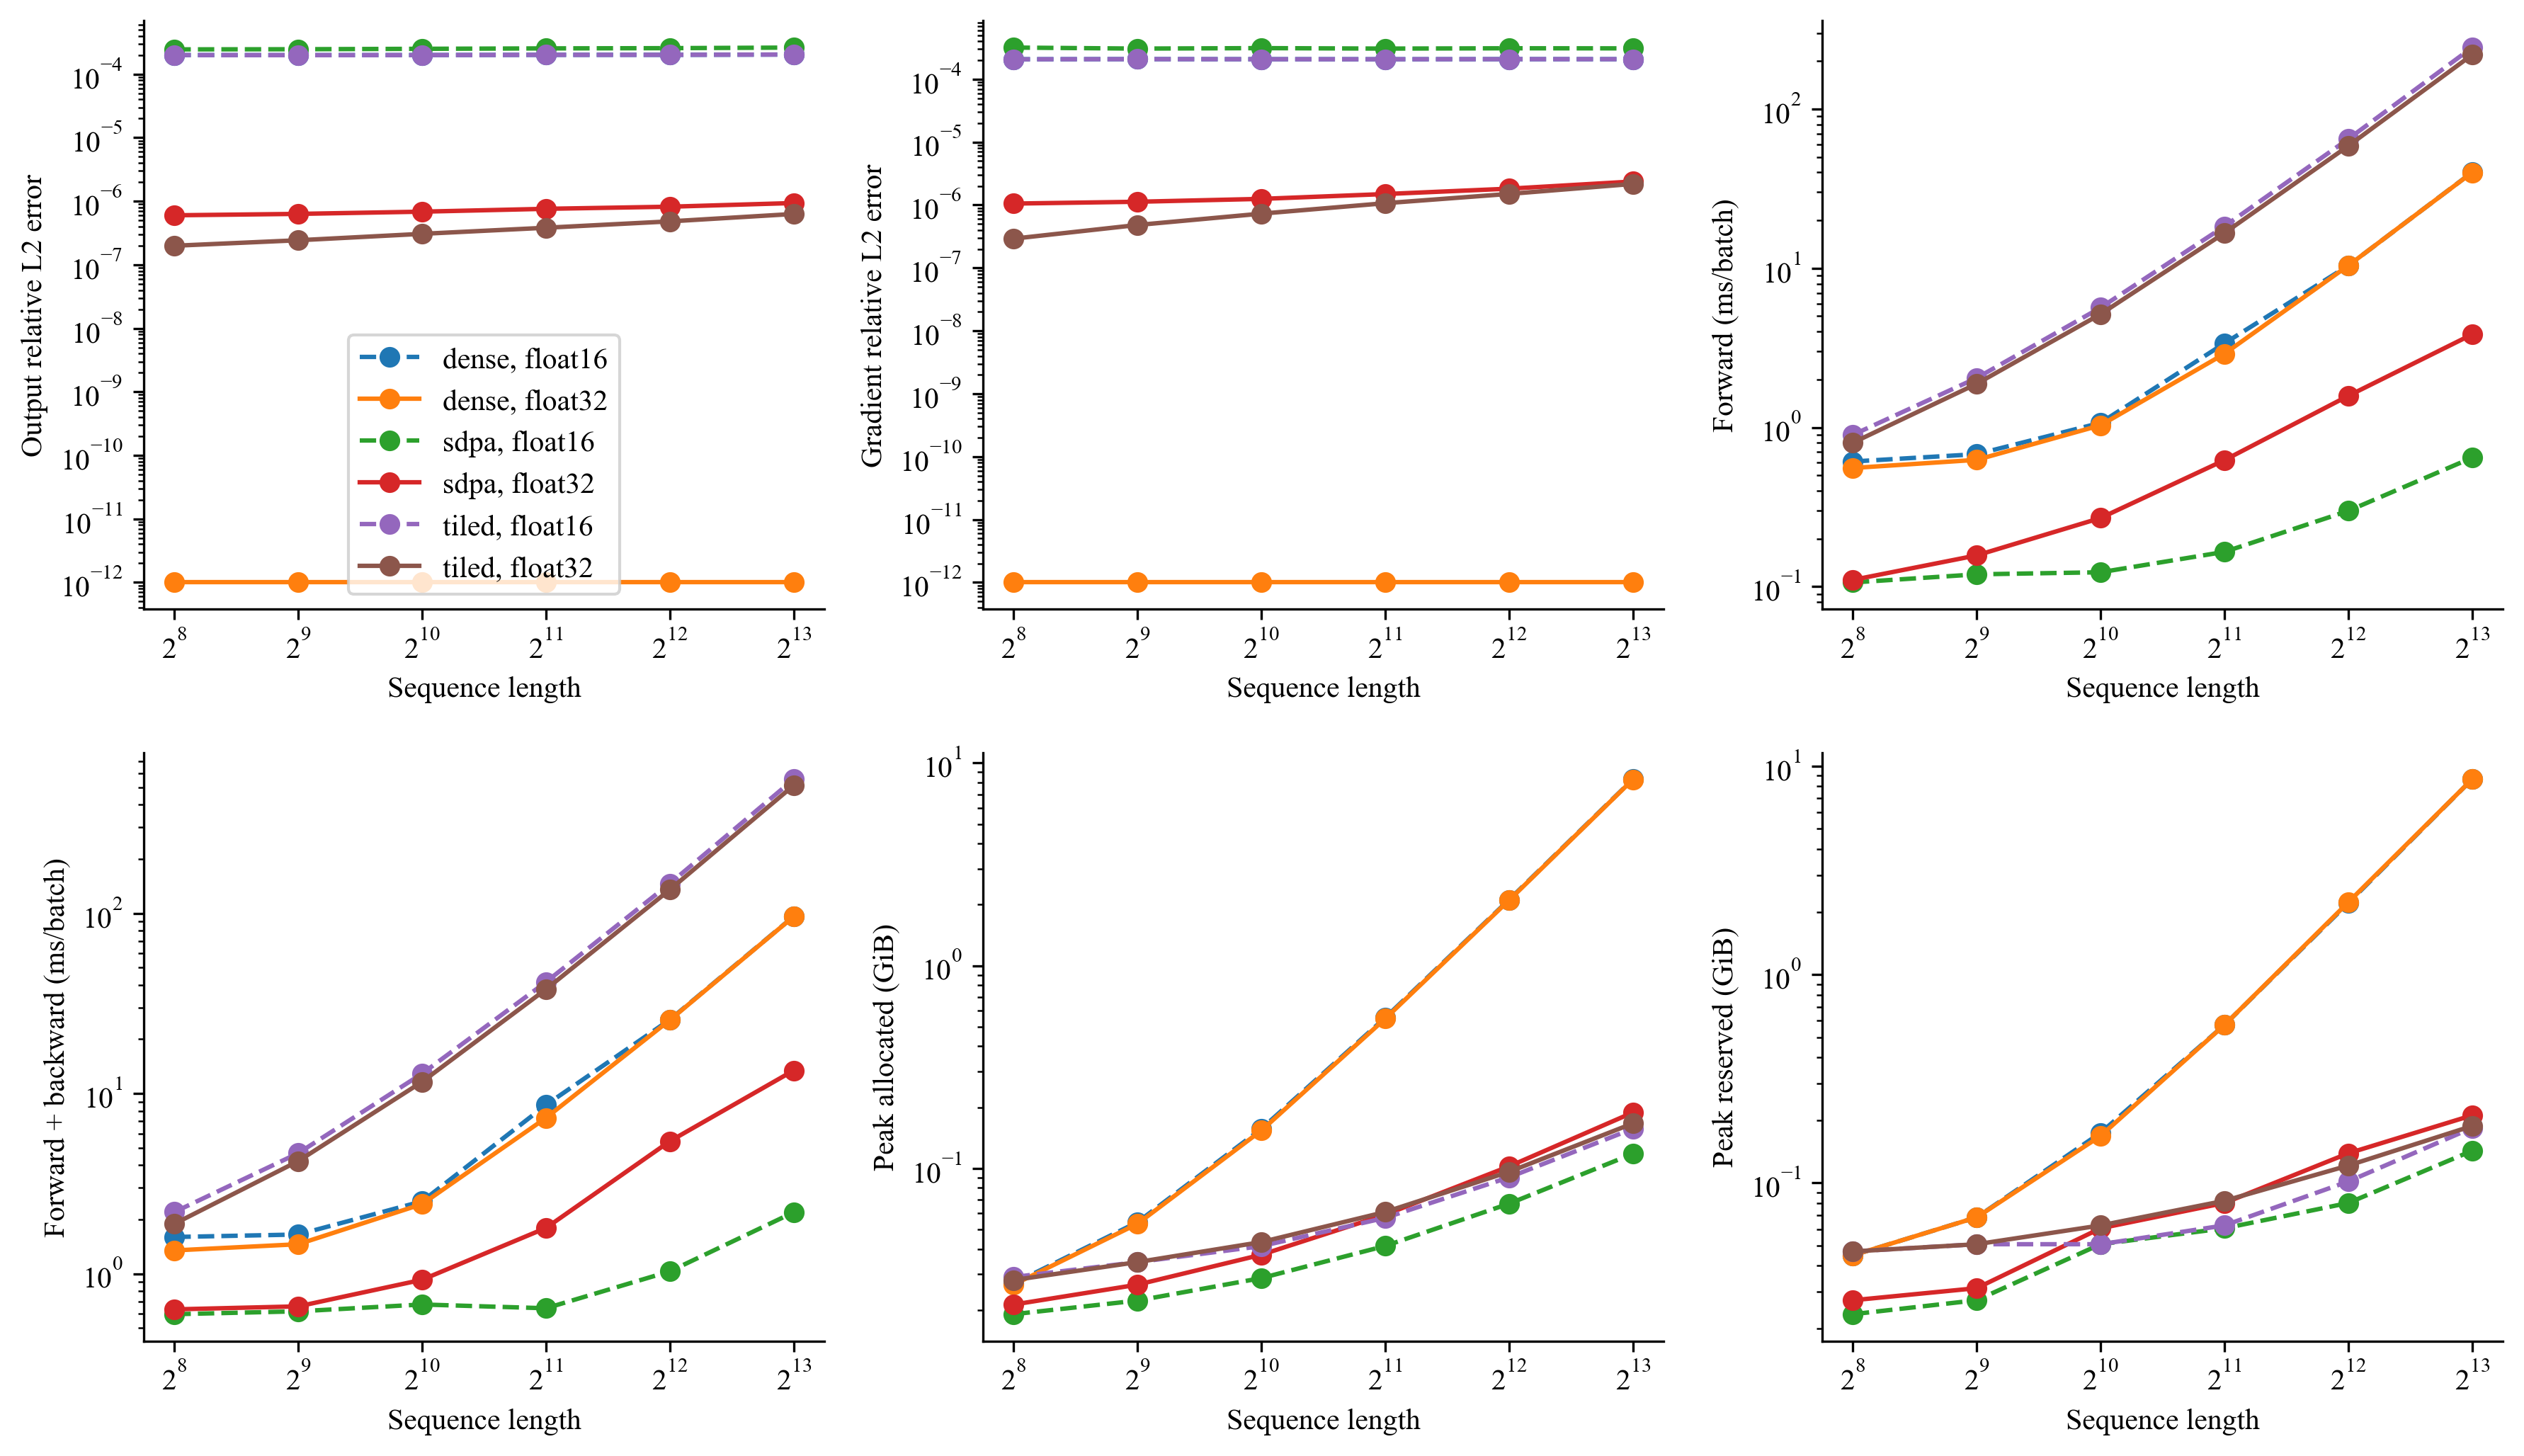

In [26]:
display_question(session, 'rq1', 'figures')


In [27]:
display_question(session, 'rq1', 'metrics')


metrics/attention/correctness.json


{'status': 'passed',
 'tiles': [{'tile': 1,
   'output': {'maximum_absolute': 3.5762786865234375e-07,
    'relative_l2': 1.3615068894523574e-07},
   'maximum_gradient_relative_l2': 2.716496396715229e-07},
  {'tile': 8,
   'output': {'maximum_absolute': 3.5762786865234375e-07,
    'relative_l2': 1.2433667961886385e-07},
   'maximum_gradient_relative_l2': 2.3651847413930227e-07},
  {'tile': 16,
   'output': {'maximum_absolute': 3.5762786865234375e-07,
    'relative_l2': 1.204511193009239e-07},
   'maximum_gradient_relative_l2': 2.433498309528659e-07},
  {'tile': 64,
   'output': {'maximum_absolute': 2.384185791015625e-07,
    'relative_l2': 1.0146578688363661e-07},
   'maximum_gradient_relative_l2': 2.0368524644709396e-07}],
 'future_perturbation': 'passed',
 'all_masked_dense_rows': 'zero output',
 'extreme_scores': 'finite',
 'tiled_backward': 'custom blockwise recomputation; Python operators, not a fused kernel'}

## RQ-2: Distance, load, attention access and trained controls

Inspect the same saved tables and figures, keeping denominators, seeds, implementation costs and recorded failures visible.


In [28]:
display_question(session, 'rq2', 'tables')


tables/mqar_training.csv
Showing 24 of 42 saved rows; complete data are in the CSV.


,id,method,train_K,train_regime,seed,status,completed_updates,trainable_parameters,training_seconds,skipped_optimizer_attempts,peak_allocated_bytes,initialization_sha256,final_sha256,final_training_loss
0,dense_K4_mixed_seed6304,dense,4,mixed,6304,complete,4500,437824,52.169706,0,361009664,64e7012e31507c45d753eb4ebf4f80f907dfd838ed7e81...,2a3e93c336a3dee7be55f291ffb8e8f3687c5b2ae1702a...,0.000334
1,dense_K4_mixed_seed6305,dense,4,mixed,6305,complete,4500,437824,51.546802,0,361009664,c541a279ff11b06e44154587f45f00a71c47aeeaf09c64...,cd085d1340b888493fb5d503c796c6ba18be73354c1251...,0.000365
2,dense_K4_mixed_seed6306,dense,4,mixed,6306,complete,4500,437824,51.460001,0,361009664,5e0392c54d65ad9968b2248f7f3101b011f2a3bc4063ee...,b1dc43ccf94b82f631bbd64914d357270c17d23f2dfe33...,0.000311
3,dense_K8_mixed_seed6304,dense,8,mixed,6304,complete,4500,437824,77.041878,0,361044480,64e7012e31507c45d753eb4ebf4f80f907dfd838ed7e81...,1faeed07eeadd10d0d82129f58e96ca947d77e15bd1284...,0.000274
4,dense_K8_mixed_seed6305,dense,8,mixed,6305,complete,4500,437824,75.700056,1,361044480,c541a279ff11b06e44154587f45f00a71c47aeeaf09c64...,6732375da0d7dd710597c19cd374d1fddff090365673bc...,0.000313
5,dense_K8_mixed_seed6306,dense,8,mixed,6306,complete,4500,437824,76.421185,0,361044480,5e0392c54d65ad9968b2248f7f3101b011f2a3bc4063ee...,6dbb5f78e0dfab079b55bdf8d324973c776ea43d36d3b2...,0.000274
6,dense_K16_mixed_seed6304,dense,16,mixed,6304,complete,4500,437824,122.280151,0,361114112,64e7012e31507c45d753eb4ebf4f80f907dfd838ed7e81...,438dfce2ed0f2bc92ec175992819bdce732f25f049ab89...,0.000323
7,dense_K16_mixed_seed6305,dense,16,mixed,6305,complete,4500,437824,123.375745,0,361114112,c541a279ff11b06e44154587f45f00a71c47aeeaf09c64...,d1cd9b174acf16ba2eda8570a9a70a7728c9fee60b429c...,0.000287
8,dense_K16_mixed_seed6306,dense,16,mixed,6306,complete,4500,437824,124.181242,0,361114112,5e0392c54d65ad9968b2248f7f3101b011f2a3bc4063ee...,dbd22e15ca6c82b1efdae78660610d6da26fb718424f96...,0.000328
9,dense_K16_near_seed6304,dense,16,near,6304,complete,4500,437824,56.485758,0,361114112,64e7012e31507c45d753eb4ebf4f80f907dfd838ed7e81...,24232a1d74ee983bc0bcfed86918f55648784882cfe7c4...,0.000224


tables/mqar_accuracy.csv
Showing 24 of 486 saved rows; complete data are in the CSV.


,id,method,train_K,train_regime,seed,training_id,test_method,test_only_mask,status,test_K,regime,examples,queries,correct,accuracy,mean_query_nll,chance_label_space,chance_present_values,denominator
0,dense_K4_mixed_seed6304,dense,4,mixed,6304,dense_K4_mixed_seed6304,dense,False,complete,4,near,1024,4096,4096,1.000000,0.000508,0.015625,0.2500,all supervised query positions; no next-token ...
1,dense_K4_mixed_seed6304,dense,4,mixed,6304,dense_K4_mixed_seed6304,dense,False,complete,4,far,1024,4096,4096,1.000000,0.000332,0.015625,0.2500,all supervised query positions; no next-token ...
2,dense_K4_mixed_seed6304,dense,4,mixed,6304,dense_K4_mixed_seed6304,dense,False,complete,4,mixed,1024,4096,4096,1.000000,0.000359,0.015625,0.2500,all supervised query positions; no next-token ...
3,dense_K4_mixed_seed6304,dense,4,mixed,6304,dense_K4_mixed_seed6304,dense,False,complete,8,near,1024,8192,5331,0.650757,2.869054,0.015625,0.1250,all supervised query positions; no next-token ...
4,dense_K4_mixed_seed6304,dense,4,mixed,6304,dense_K4_mixed_seed6304,dense,False,complete,8,far,1024,8192,5226,0.637939,2.892779,0.015625,0.1250,all supervised query positions; no next-token ...
5,dense_K4_mixed_seed6304,dense,4,mixed,6304,dense_K4_mixed_seed6304,dense,False,complete,8,mixed,1024,8192,5270,0.643311,2.905905,0.015625,0.1250,all supervised query positions; no next-token ...
6,dense_K4_mixed_seed6304,dense,4,mixed,6304,dense_K4_mixed_seed6304,dense,False,complete,16,near,1024,16384,5462,0.333374,5.802086,0.015625,0.0625,all supervised query positions; no next-token ...
7,dense_K4_mixed_seed6304,dense,4,mixed,6304,dense_K4_mixed_seed6304,dense,False,complete,16,far,1024,16384,5388,0.328857,5.738796,0.015625,0.0625,all supervised query positions; no next-token ...
8,dense_K4_mixed_seed6304,dense,4,mixed,6304,dense_K4_mixed_seed6304,dense,False,complete,16,mixed,1024,16384,5448,0.332520,5.713757,0.015625,0.0625,all supervised query positions; no next-token ...
9,dense_K4_mixed_seed6304_test_window64,dense,4,mixed,6304,dense_K4_mixed_seed6304,window,True,complete,4,near,1024,4096,4096,1.000000,0.000507,0.015625,0.2500,all supervised query positions; no next-token ...


tables/mqar_seed_dispersion.csv
Showing 24 of 162 saved rows; complete data are in the CSV.


,method,train_K,train_regime,test_method,test_only_mask,test_K,regime,mean,std,count
0,dense,4,mixed,dense,False,4,far,1.000000,0.000000,3
1,dense,4,mixed,dense,False,4,mixed,1.000000,0.000000,3
2,dense,4,mixed,dense,False,4,near,1.000000,0.000000,3
3,dense,4,mixed,dense,False,8,far,0.641398,0.025991,3
4,dense,4,mixed,dense,False,8,mixed,0.646037,0.027628,3
5,dense,4,mixed,dense,False,8,near,0.649862,0.029795,3
6,dense,4,mixed,dense,False,16,far,0.326436,0.015614,3
7,dense,4,mixed,dense,False,16,mixed,0.328084,0.016862,3
8,dense,4,mixed,dense,False,16,near,0.330017,0.017185,3
9,dense,4,mixed,window,True,4,far,0.011637,0.003053,3


figures/rq2_learning_curves.png


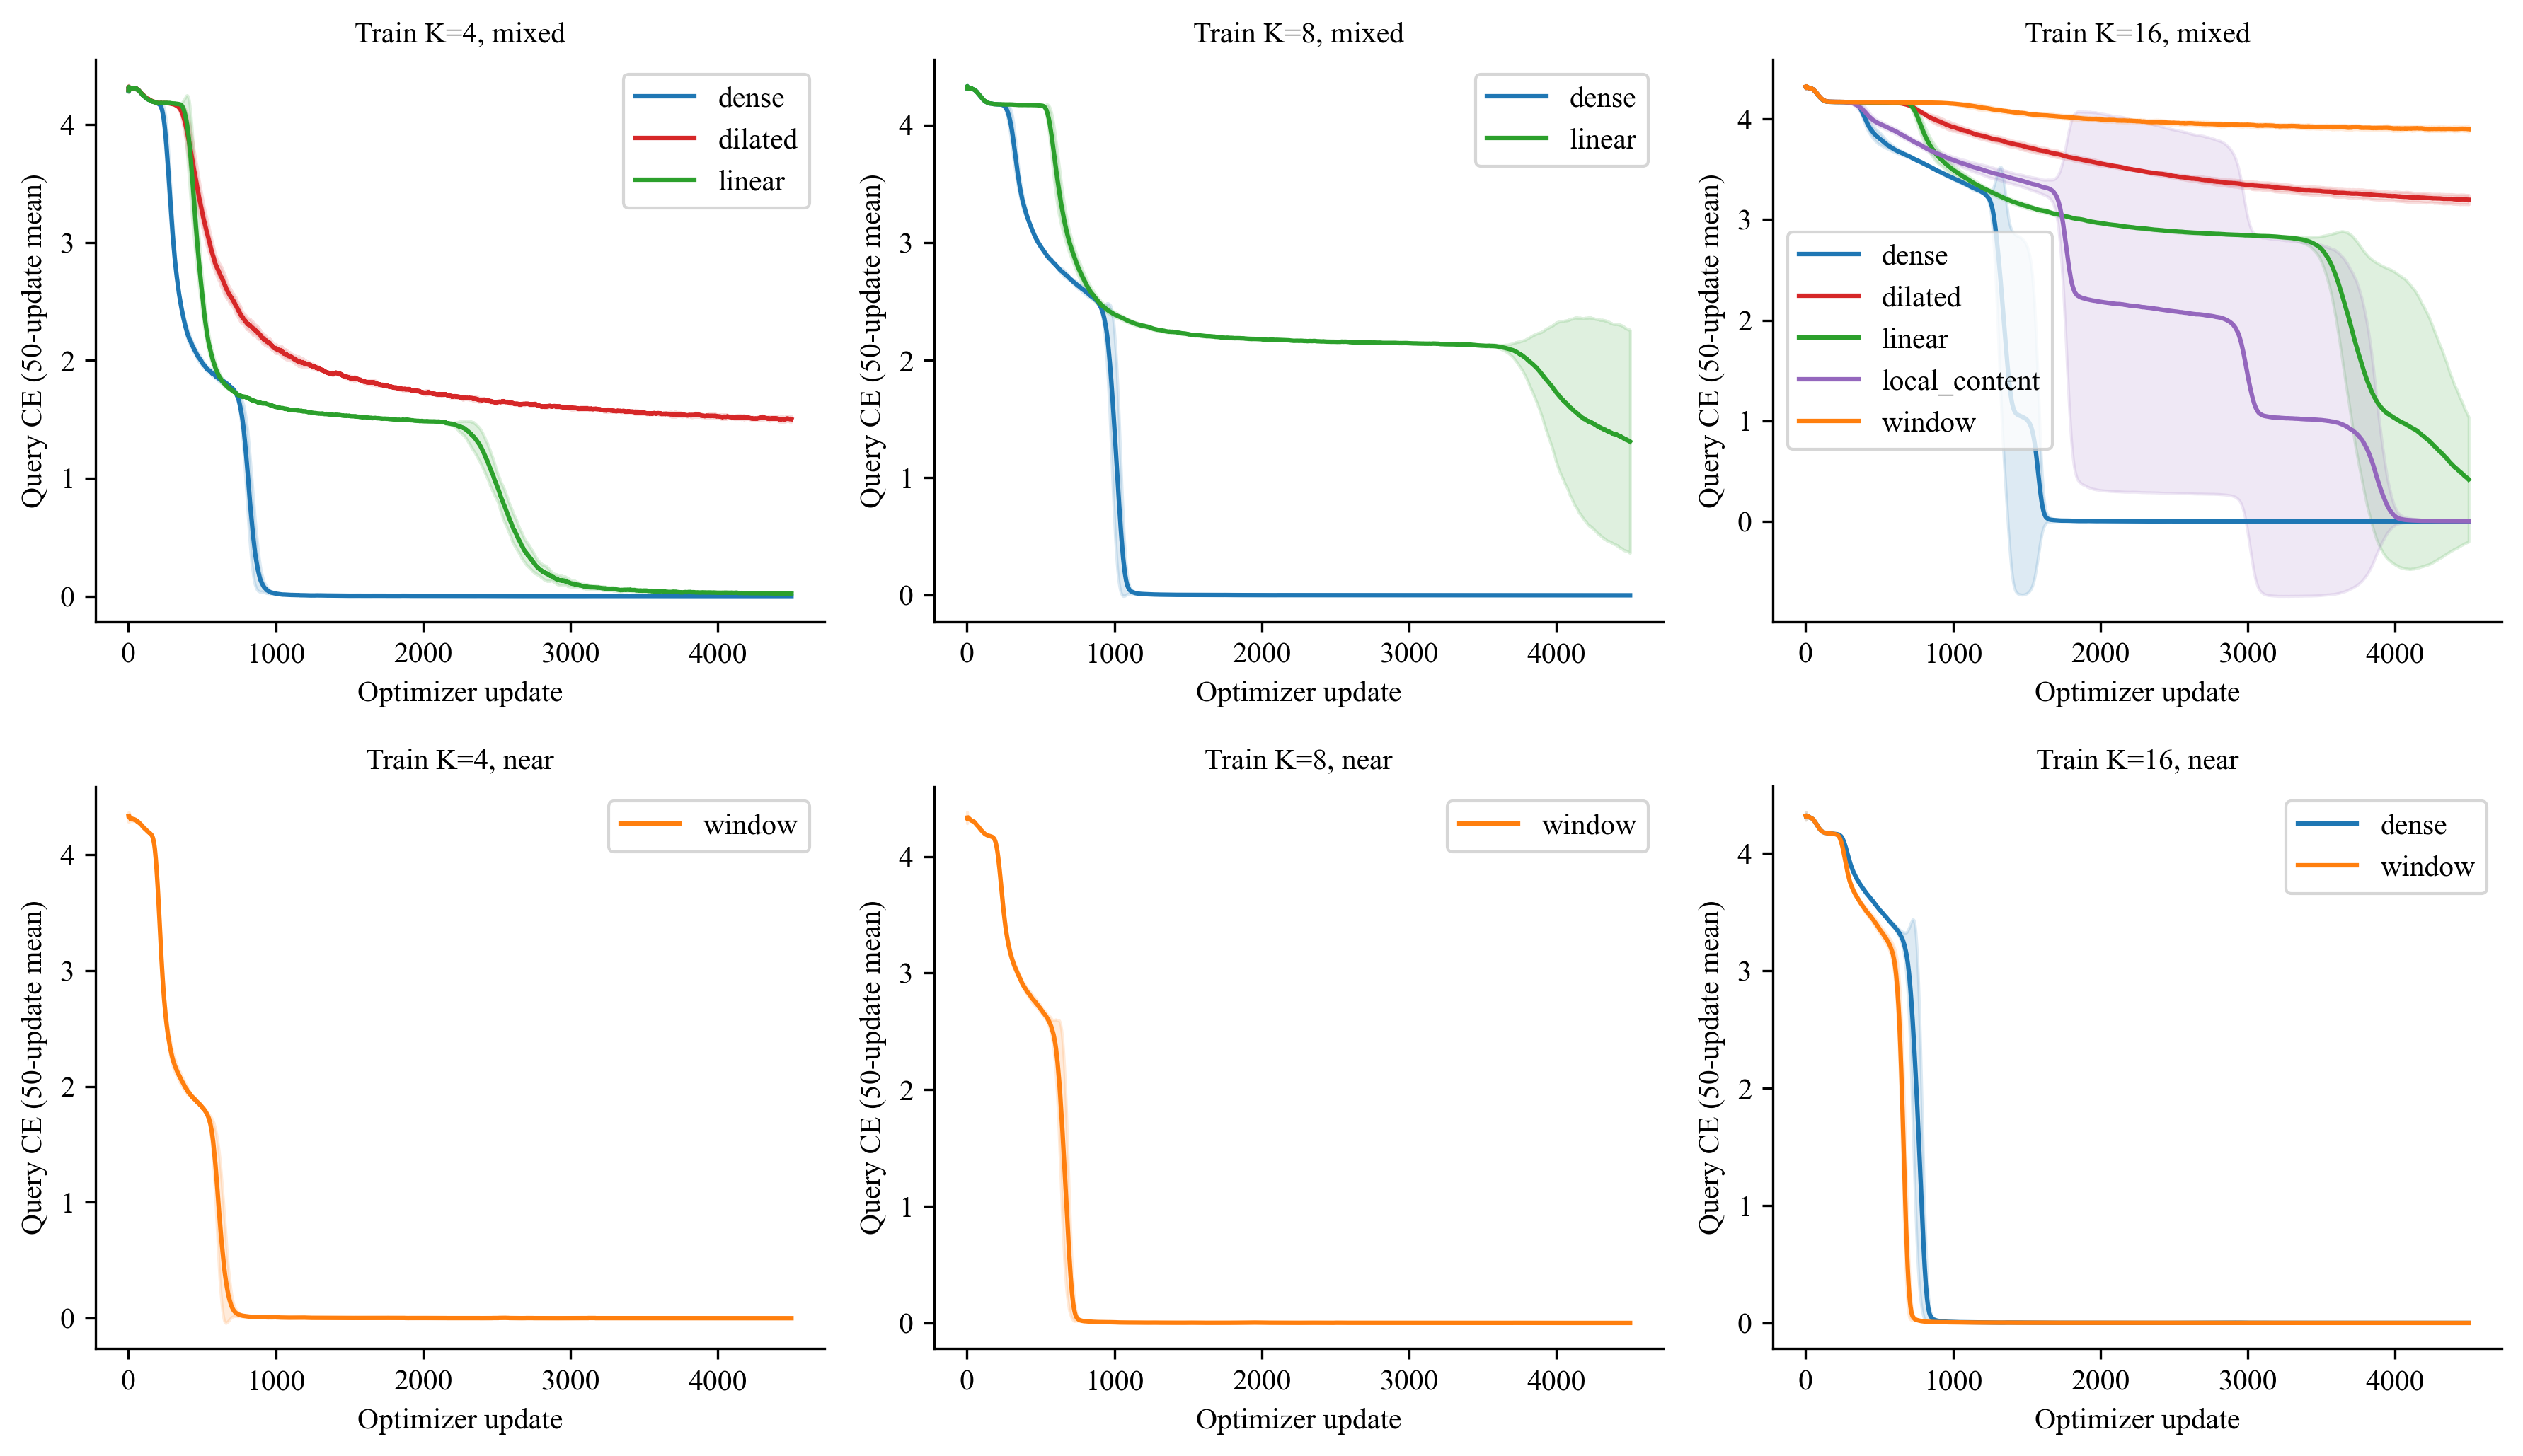

figures/rq2_distance_load.png


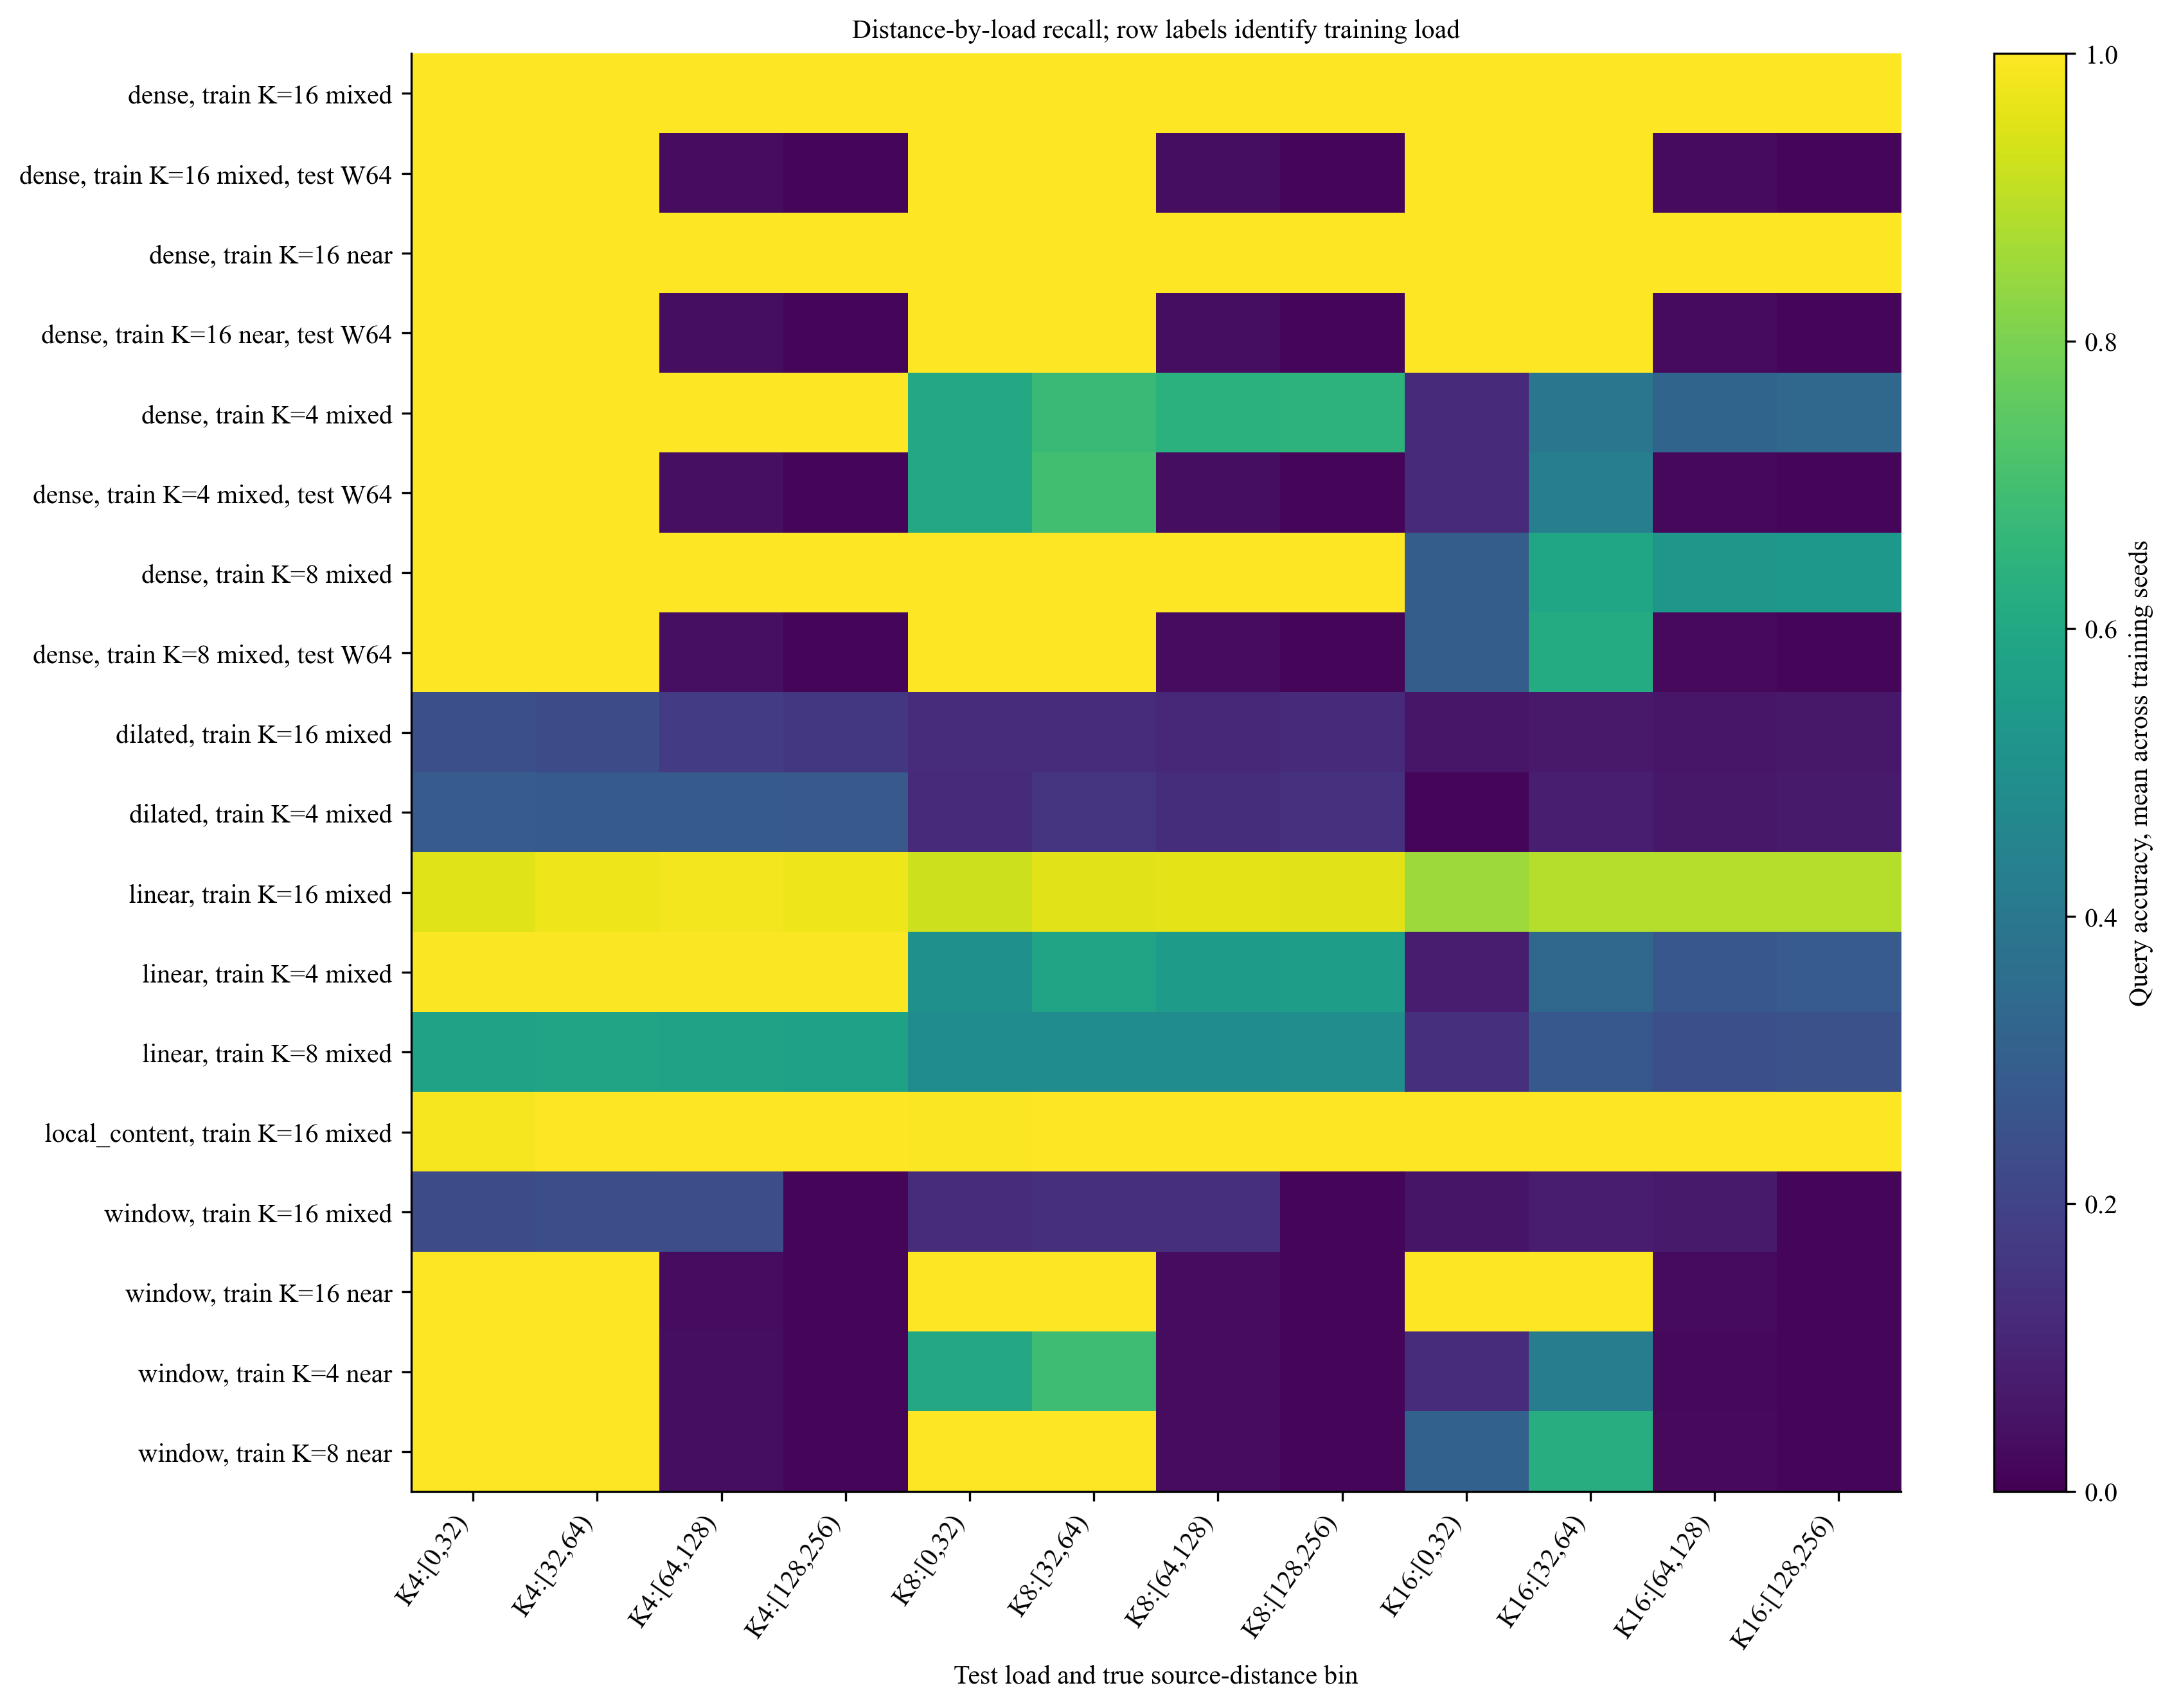

figures/rq2_regime_controls.png


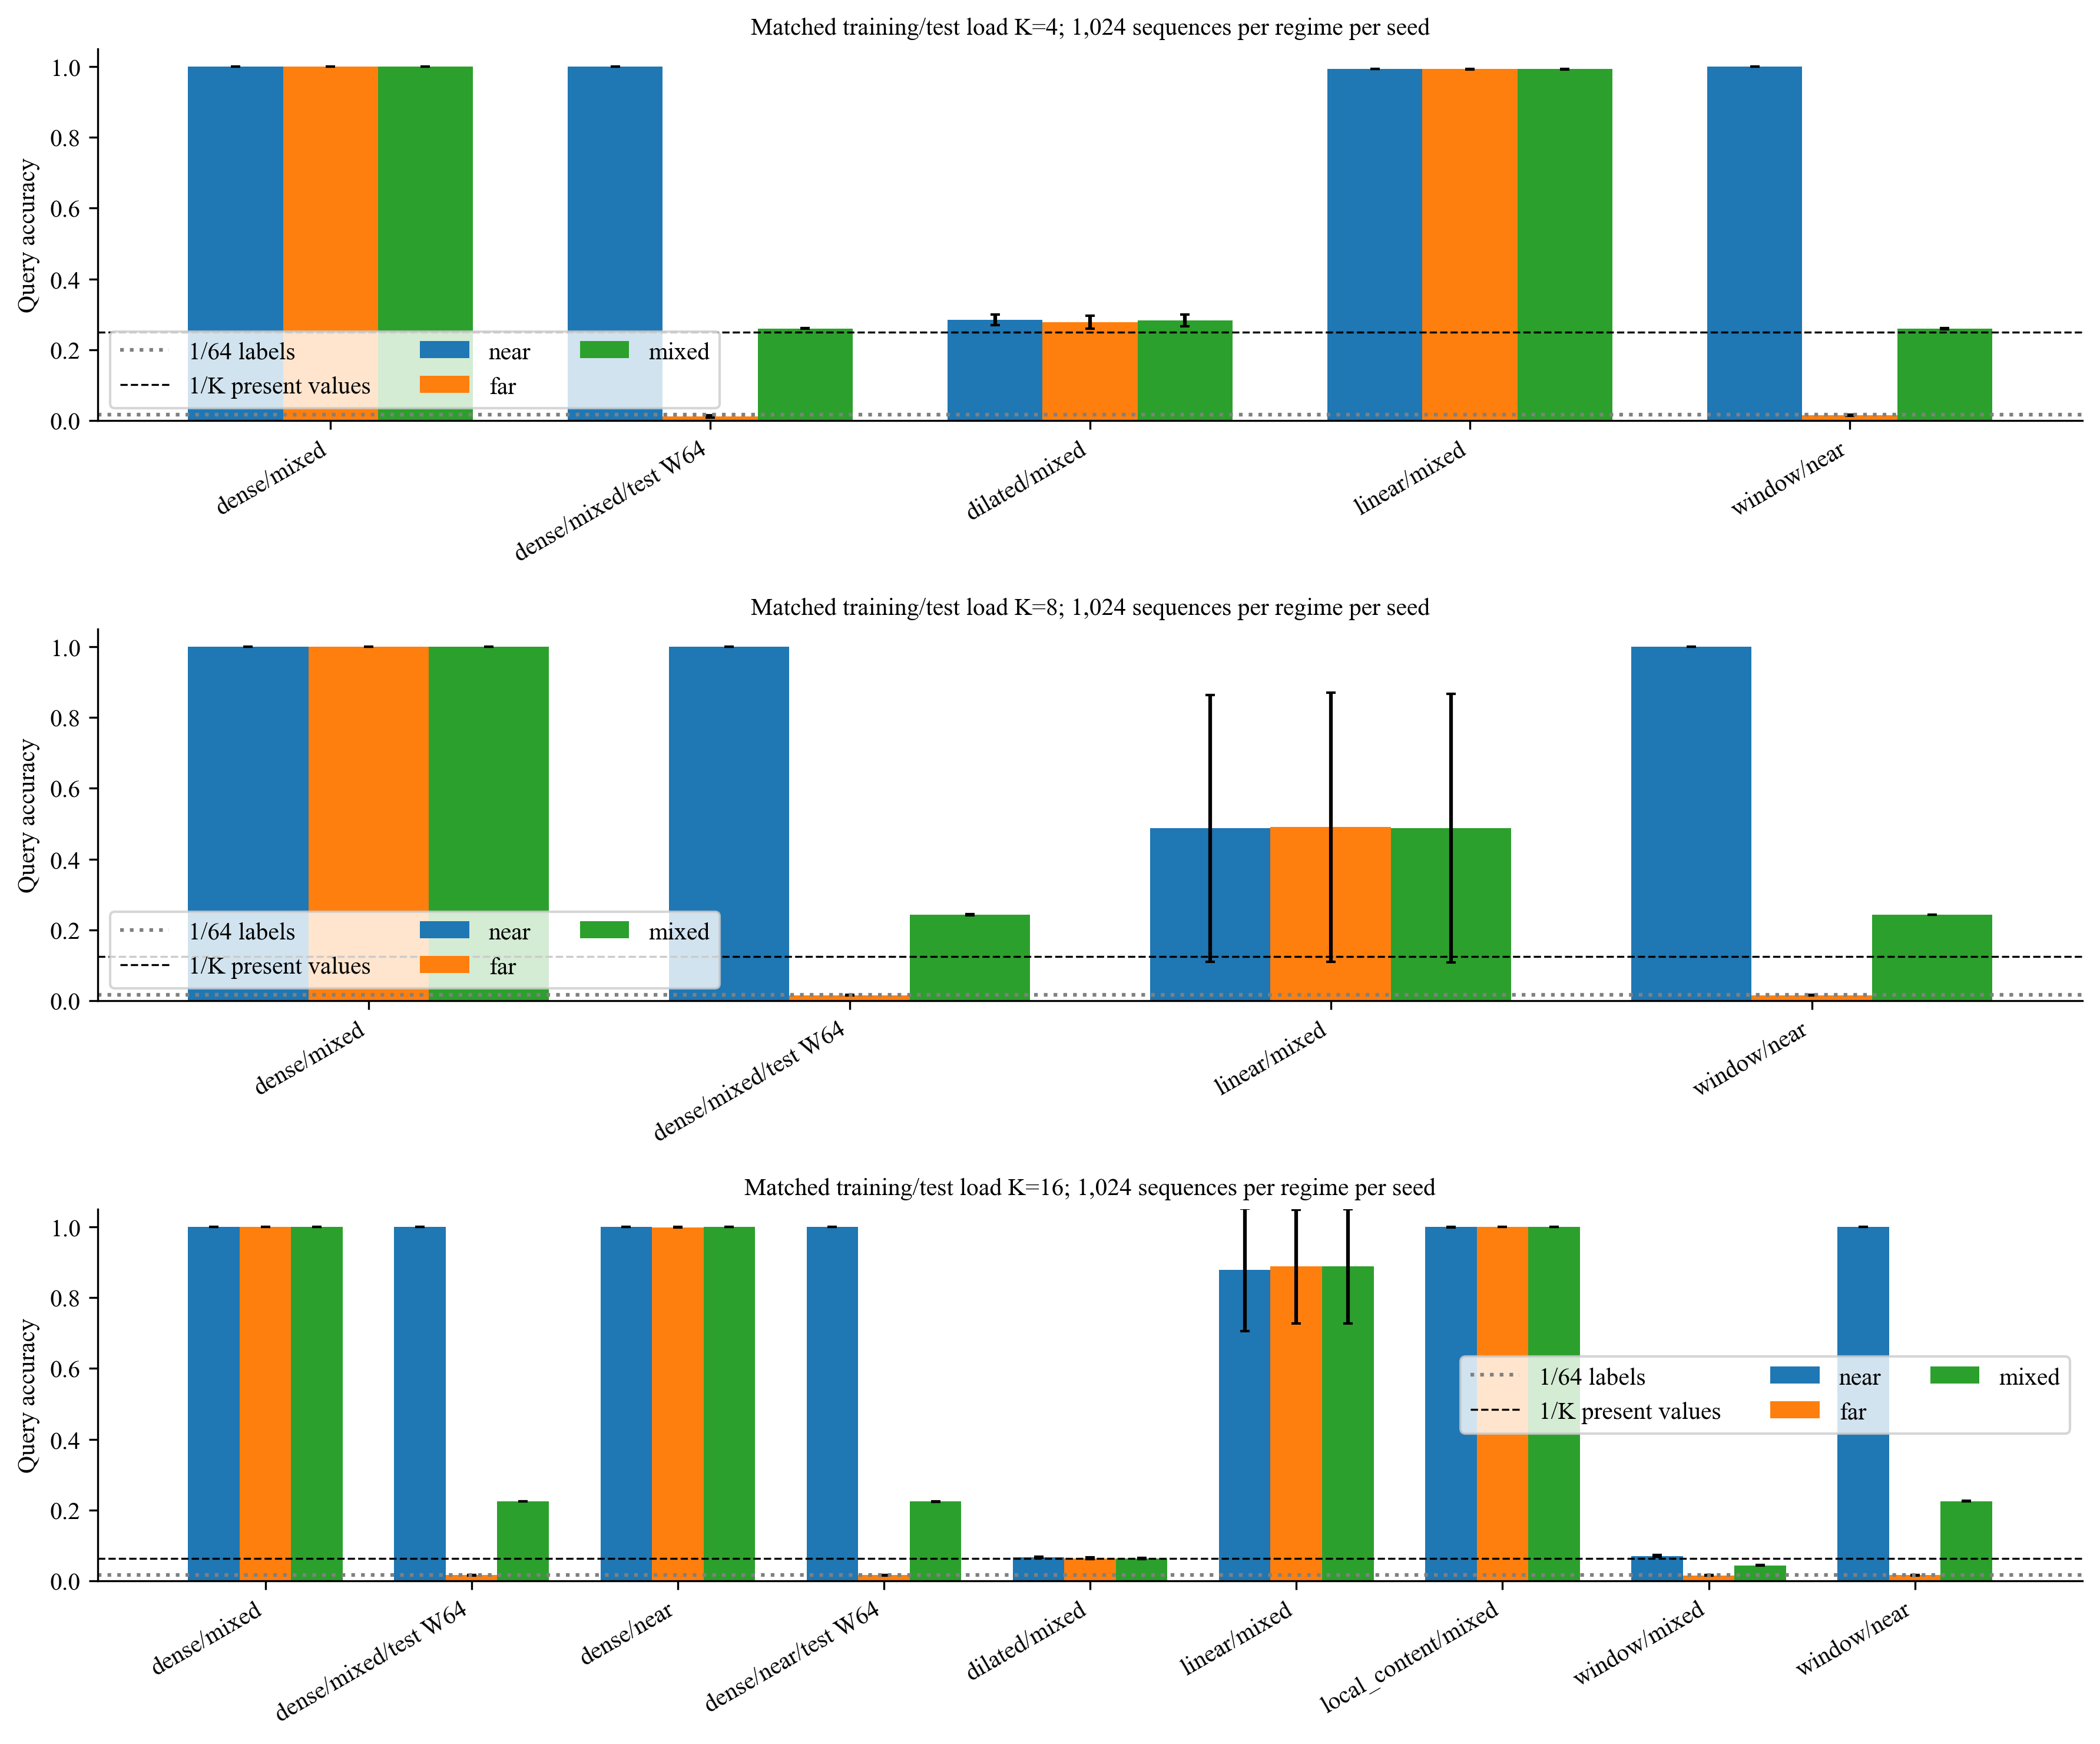

In [29]:
display_question(session, 'rq2', 'figures')


In [30]:
display_question(session, 'rq2', 'metrics')


configs/intervention_locked.json


{'method': 'local_content',
 'train_K': 16,
 'train_regime': 'mixed',
 'content_k': 64,
 'selection_rule': 'topk_64_if_dense_minus_dilated_dev_far_at_least_threshold_else_32',
 'development_gap_threshold': 0.02,
 'observed_development_far_accuracy': [{'seed': 6304,
   'dense': 1.0,
   'window': 0.01611328125,
   'dilated': 0.060546875},
  {'seed': 6305,
   'dense': 1.0,
   'window': 0.01611328125,
   'dilated': 0.05810546875},
  {'seed': 6306,
   'dense': 1.0,
   'window': 0.014892578125,
   'dilated': 0.06640625}],
 'dense_minus_dilated_mean_development_gap': 0.9383138020833334,
 'final_test_accessed': False,
 'prediction': {'metric': 'far_query_accuracy',
  'direction': 'greater_than_dilated',
  'comparator': 'dilated_K16_mixed'},
 'persistent_state': 'ordinary full-history keys and values for content score selection; no compressed recurrent state',
 'extra_trainable_parameters': 0,
 'local_heads': 2,
 'content_selected_heads': 2,
 'selection_cost': 'all causal scores plus stable sor

## RQ-3: Matched-byte KV retention and answer fidelity

Inspect the same saved tables and figures, keeping denominators, seeds, implementation costs and recorded failures visible.


In [31]:
display_question(session, 'rq3', 'tables')


tables/kv_summary.csv


,method,prompts,completed_prompts,accuracy,conditional_on_fp16_correct_accuracy,fp16_correct_prompts,reference_answer_mean_nll,post_prefill_logit_kl,reference_answer_teacher_forced_kl,actual_serialized_prefix_bytes,fraction_full_fp16_bytes,evidence_retention_fraction,prefill_seconds,question_importance_seconds,packed_encode_seconds,question_suffix_seconds,teacher_forced_scoring_seconds,peak_allocated_bytes,mean_decode_seconds,truncated_prompts
0,fp16,180,180,1.000000,1.000000,180,0.000723,0.000000,0.000000,1.121732e+08,1.000000,1.000000,0.09991,0.000000,0.001152,0.040208,0.314842,3.608532e+09,0.168038,0
1,sink_recent,180,180,0.333333,0.333333,180,1.543909,2.066424,1.541027,3.209102e+07,0.286949,0.333333,0.09991,0.000000,0.006292,0.041529,0.321873,3.525676e+09,0.173431,0
2,question_aware,180,180,1.000000,1.000000,180,0.000711,0.000517,0.000088,3.209102e+07,0.286949,1.000000,0.09991,0.060371,0.003640,0.042017,0.317803,3.504150e+09,0.168683,0
3,int4_token,180,180,0.000000,0.000000,180,6.748106,5.934017,6.745062,3.211522e+07,0.287196,1.000000,0.09991,0.000000,0.054060,1.749026,0.517665,3.504150e+09,1.624038,180
4,int4_channel,180,180,1.000000,1.000000,180,0.001025,0.001264,0.000223,3.211522e+07,0.287196,1.000000,0.09991,0.000000,0.054974,1.779524,0.525943,3.504150e+09,0.266912,0
5,hybrid,180,180,0.977778,0.977778,180,0.009358,0.006856,0.008548,3.089887e+07,0.276084,0.994033,0.09991,0.060371,0.064970,2.124994,0.620185,3.504150e+09,0.317613,0


tables/kv_paired_intervals.csv


,method,reference,difference,ci_low,ci_high,paired_prompts,resamples,unit,failed_runs_counted_as_incorrect
0,sink_recent,fp16,-0.666667,-0.733333,-0.600000,180,2000,fraction; multiply by 100 for percentage points,True
1,question_aware,fp16,0.000000,0.000000,0.000000,180,2000,fraction; multiply by 100 for percentage points,True
2,int4_token,fp16,-1.000000,-1.000000,-1.000000,180,2000,fraction; multiply by 100 for percentage points,True
3,int4_channel,fp16,0.000000,0.000000,0.000000,180,2000,fraction; multiply by 100 for percentage points,True
4,hybrid,fp16,-0.022222,-0.044444,-0.005556,180,2000,fraction; multiply by 100 for percentage points,True
5,question_aware,sink_recent,0.666667,0.600000,0.733333,180,2000,fraction; multiply by 100 for percentage points,True
6,int4_channel,int4_token,1.000000,1.000000,1.000000,180,2000,fraction; multiply by 100 for percentage points,True
7,hybrid,question_aware,-0.022222,-0.044444,-0.005556,180,2000,fraction; multiply by 100 for percentage points,True
8,hybrid,int4_channel,-0.022222,-0.044444,-0.005556,180,2000,fraction; multiply by 100 for percentage points,True


tables/kv_factorial.csv
Showing 24 of 108 saved rows; complete data are in the CSV.


,method,target_tokens,position,distractors,interpretation,prompts,completed_prompts,accuracy,conditional_on_fp16_correct_accuracy,fp16_correct_prompts,...,fraction_full_fp16_bytes,evidence_retention_fraction,prefill_seconds,question_importance_seconds,packed_encode_seconds,question_suffix_seconds,teacher_forced_scoring_seconds,peak_allocated_bytes,mean_decode_seconds,truncated_prompts
0,fp16,2048,start,0,descriptive ten-prompt cell,10,10,1.0,1.0,10,...,1.000000,1.0,0.065373,0.0,0.001195,0.039872,0.310388,3.483474e+09,0.167054,0
1,fp16,2048,start,2,descriptive ten-prompt cell,10,10,1.0,1.0,10,...,1.000000,1.0,0.066512,0.0,0.001109,0.039507,0.308369,3.483613e+09,0.165472,0
2,fp16,2048,start,8,descriptive ten-prompt cell,10,10,1.0,1.0,10,...,1.000000,1.0,0.066416,0.0,0.001177,0.039584,0.313500,3.482833e+09,0.166189,0
3,fp16,2048,middle,0,descriptive ten-prompt cell,10,10,1.0,1.0,10,...,1.000000,1.0,0.066545,0.0,0.001132,0.039817,0.310087,3.484007e+09,0.166508,0
4,fp16,2048,middle,2,descriptive ten-prompt cell,10,10,1.0,1.0,10,...,1.000000,1.0,0.066553,0.0,0.001162,0.039963,0.316601,3.483605e+09,0.167754,0
5,fp16,2048,middle,8,descriptive ten-prompt cell,10,10,1.0,1.0,10,...,1.000000,1.0,0.066308,0.0,0.001138,0.039794,0.309002,3.482844e+09,0.168110,0
6,fp16,2048,end,0,descriptive ten-prompt cell,10,10,1.0,1.0,10,...,1.000000,1.0,0.066474,0.0,0.001189,0.040784,0.310496,3.483978e+09,0.167101,0
7,fp16,2048,end,2,descriptive ten-prompt cell,10,10,1.0,1.0,10,...,1.000000,1.0,0.066448,0.0,0.001191,0.040313,0.323404,3.483222e+09,0.170563,0
8,fp16,2048,end,8,descriptive ten-prompt cell,10,10,1.0,1.0,10,...,1.000000,1.0,0.066217,0.0,0.001246,0.041679,0.316532,3.482833e+09,0.169111,0
9,fp16,4096,start,0,descriptive ten-prompt cell,10,10,1.0,1.0,10,...,1.000000,1.0,0.134672,0.0,0.001127,0.040037,0.313408,3.734741e+09,0.166363,0


figures/rq3_kv_fidelity.png


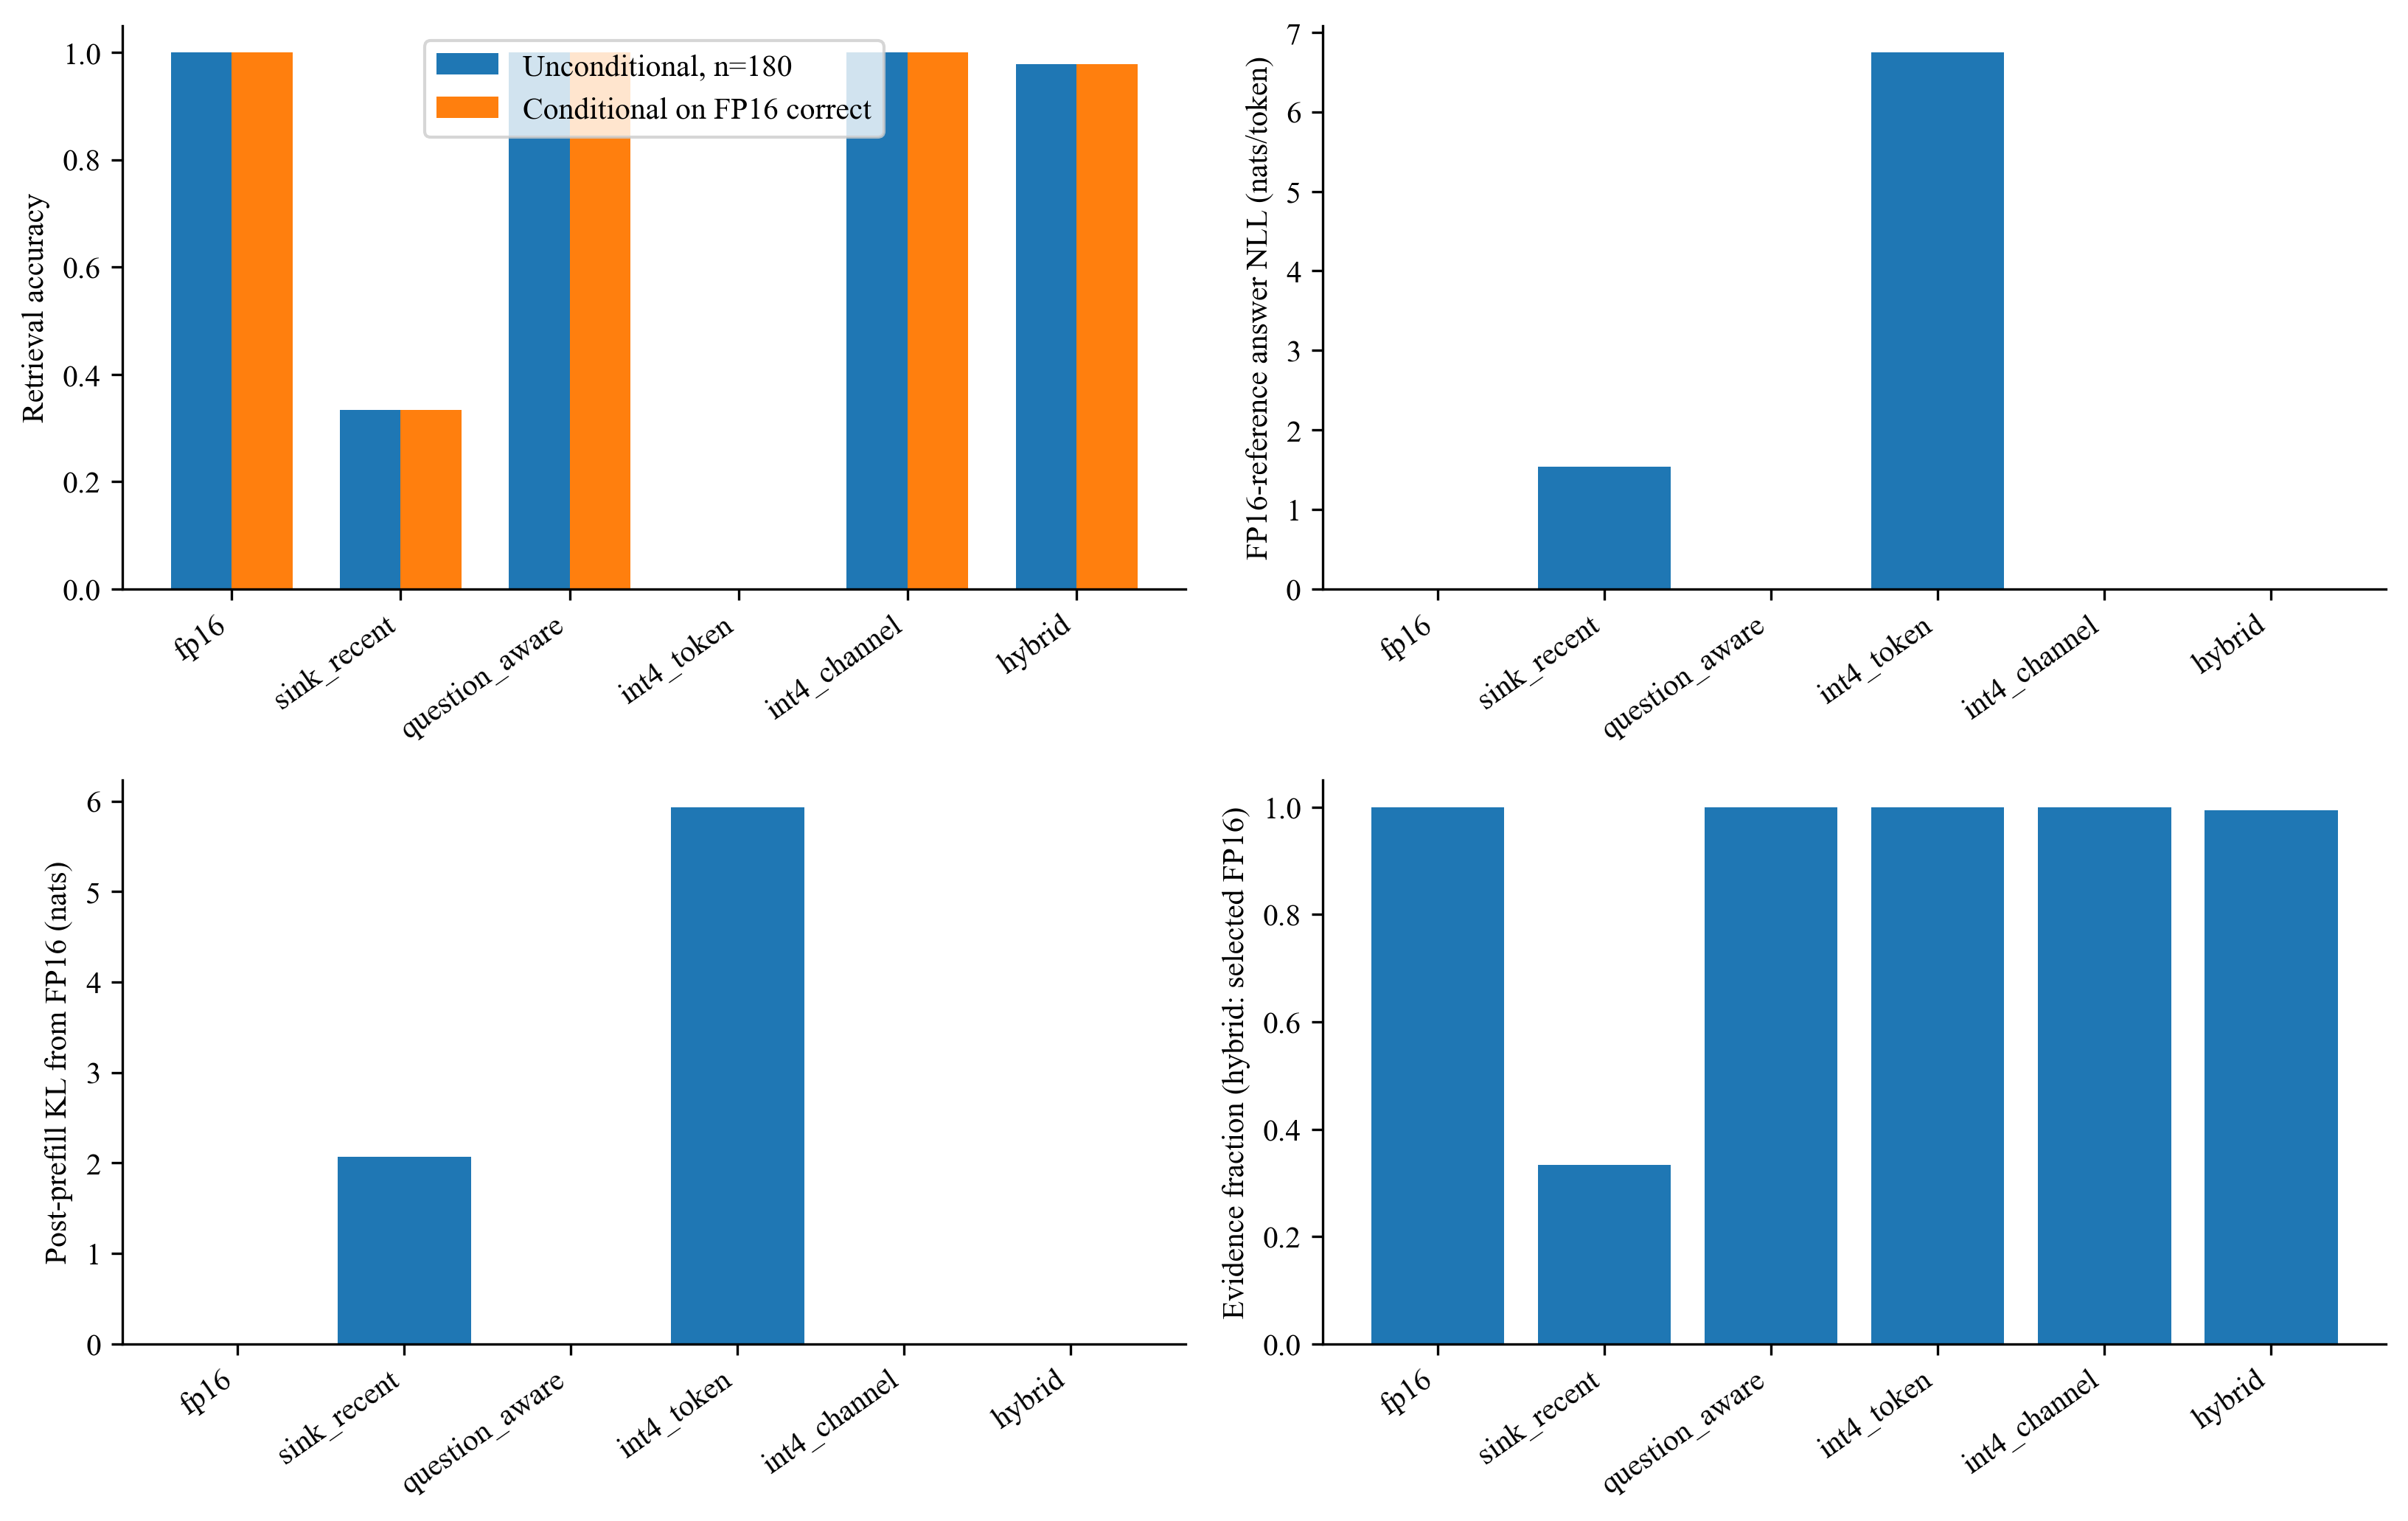

figures/rq3_kv_factorial.png


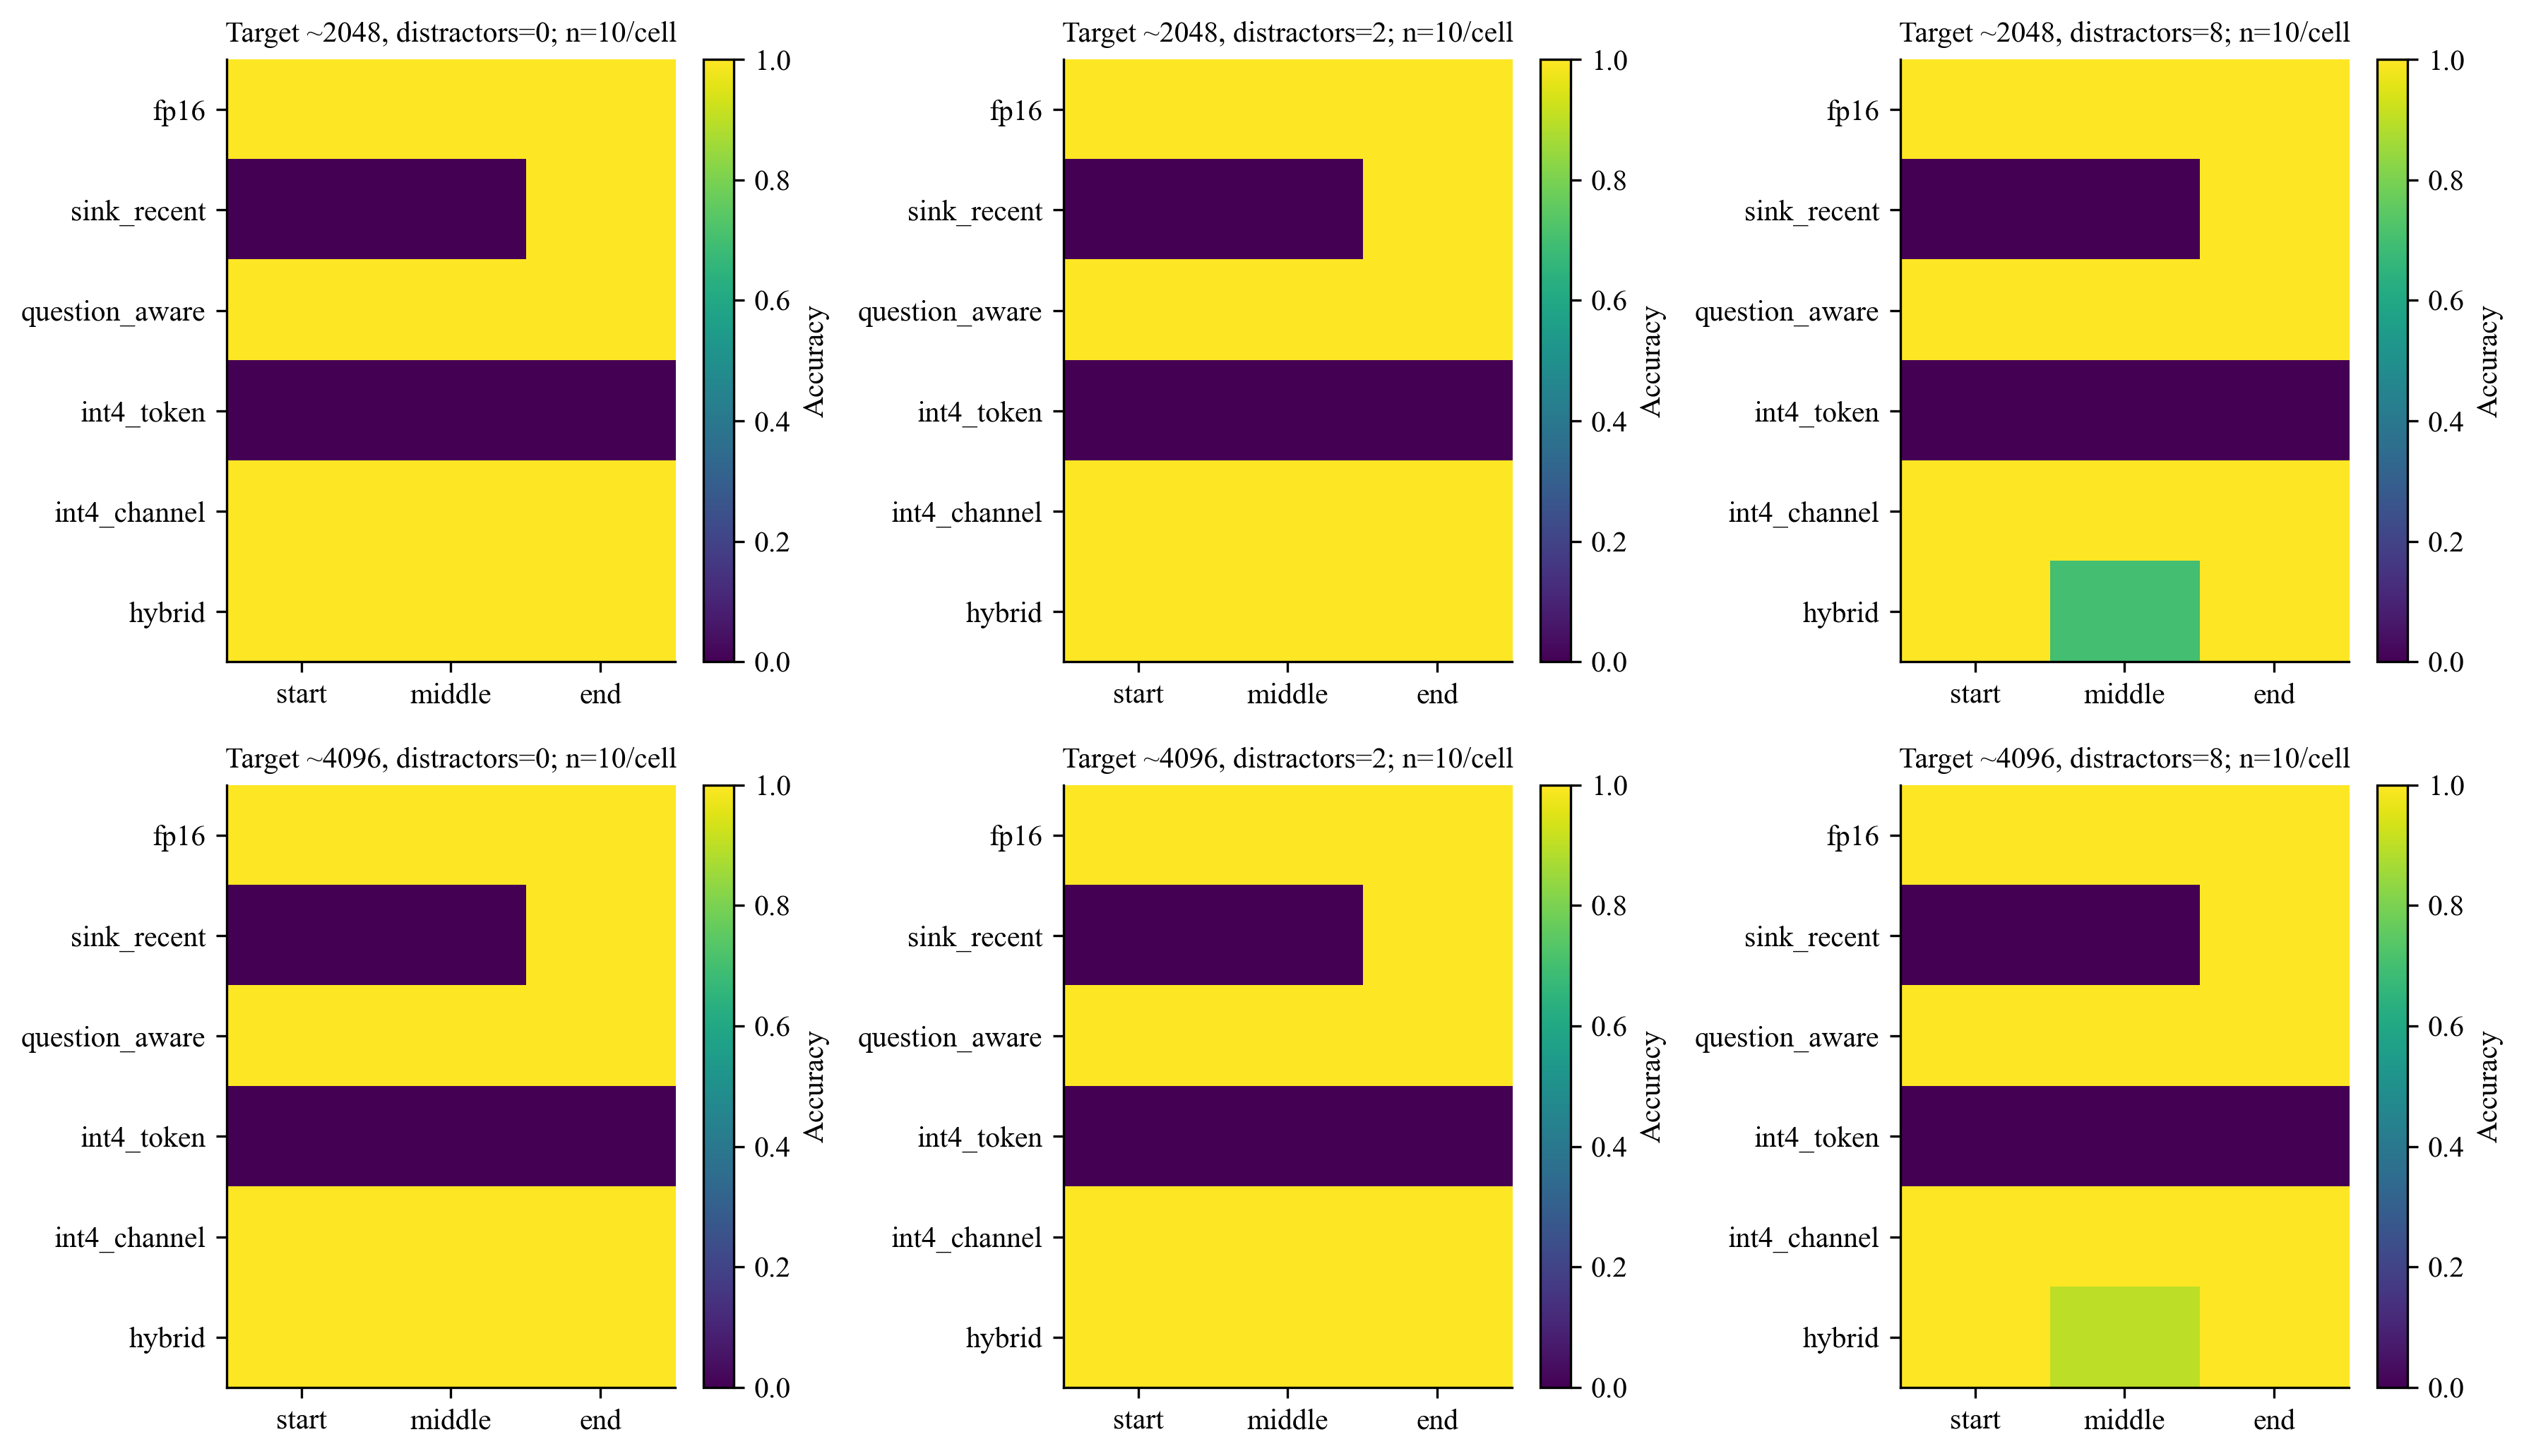

In [32]:
display_question(session, 'rq3', 'figures')


In [33]:
display_question(session, 'rq3', 'metrics')


metrics/kv/reference_checks.json


{'status': 'passed',
 'cases': [{'id': 'KV-2048-start-0-00',
   'direct_vs_split': {'maximum_absolute': 0.0546875,
    'relative_l2': 0.0029534203931689262},
   'split_vs_retained_100_percent': {'maximum_absolute': 0.0,
    'relative_l2': 0.0},
   'three_step_greedy_tokens': [17, 21, 23],
   'physical_tokens': 2660,
   'absolute_tokens': 2660,
   'status': 'passed'},
  {'id': 'KV-2048-middle-0-00',
   'direct_vs_split': {'maximum_absolute': 0.0546875,
    'relative_l2': 0.003777835750952363},
   'split_vs_retained_100_percent': {'maximum_absolute': 0.0,
    'relative_l2': 0.0},
   'three_step_greedy_tokens': [18, 17, 15],
   'physical_tokens': 2669,
   'absolute_tokens': 2669,
   'status': 'passed'},
  {'id': 'KV-2048-end-0-00',
   'direct_vs_split': {'maximum_absolute': 0.03515625,
    'relative_l2': 0.0023559920955449343},
   'split_vs_retained_100_percent': {'maximum_absolute': 0.0,
    'relative_l2': 0.0},
   'three_step_greedy_tokens': [18, 23, 22],
   'physical_tokens': 2664,
   

## RQ-4: Selection, packing and actual execution overhead

Inspect the same saved tables and figures, keeping denominators, seeds, implementation costs and recorded failures visible.


In [34]:
display_question(session, 'rq4', 'tables')


tables/mqar_operator_resources.csv


,method,batch,heads,length,head_dimension,attended_pairs,content_selection_score_pairs,content_causal_candidate_pairs,explicit_content_score_bytes,full_sort_index_bytes,theoretical_incremental_state_bytes,explicit_mask_bytes,mask_scope,implementation,state_note,observed_operators,status,median_ms,peak_allocated_bytes,additional_peak_allocated_bytes
0,dense,2,4,256,32,263168.0,0,0,0,0,262144,0,boolean mask passed to SDPA; construction/sele...,SDPA,hypothetical minimal incremental per-head buff...,"['aten::_flash_attention_forward', 'aten::_sca...",complete,0.106911,17572864,140288
1,window,2,4,256,32,114944.0,0,0,0,0,65536,65536,boolean mask passed to SDPA; construction/sele...,dense boolean mask + SDPA,hypothetical minimal incremental per-head buff...,"['aten::_efficient_attention_forward', 'aten::...",complete,0.278708,18089984,657408
2,linear,2,4,256,32,NaN,0,0,0,0,33792,0,boolean mask passed to SDPA; construction/sele...,chunked FP32 prefix tensors; autograd retains ...,hypothetical minimal incremental per-head buff...,['explicit_chunked_elu1_prefix_state'],complete,1.303928,24971264,7538688
3,dilated,2,4,256,32,90752.0,0,0,0,0,162304,262144,boolean mask passed to SDPA; construction/sele...,dense boolean mask + SDPA,hypothetical minimal incremental per-head buff...,"['aten::_efficient_attention_forward', 'aten::...",complete,0.456225,18679808,1247232
4,local_content,2,4,256,32,114944.0,262144,131584,1048576,2097152,163840,65536,boolean mask passed to SDPA; construction/sele...,"dense scores, stable sort and dense selected a...",hypothetical minimal incremental per-head buff...,"['aten::_efficient_attention_forward', 'aten::...",complete,0.879641,23527424,6094848
5,dense,2,4,1024,32,4198400.0,0,0,0,0,1048576,0,boolean mask passed to SDPA; construction/sele...,SDPA,hypothetical minimal incremental per-head buff...,"['aten::_flash_attention_forward', 'aten::_sca...",complete,0.160731,23495680,4883456
6,window,2,4,1024,32,508160.0,0,0,0,0,65536,1048576,boolean mask passed to SDPA; construction/sele...,dense boolean mask + SDPA,hypothetical minimal incremental per-head buff...,"['aten::_efficient_attention_forward', 'aten::...",complete,0.363653,29106176,10493952
7,linear,2,4,1024,32,NaN,0,0,0,0,33792,0,boolean mask passed to SDPA; construction/sele...,chunked FP32 prefix tensors; autograd retains ...,hypothetical minimal incremental per-head buff...,['explicit_chunked_elu1_prefix_state'],complete,4.283104,29296640,10684416
8,dilated,2,4,1024,32,483968.0,0,0,0,0,162304,4194304,boolean mask passed to SDPA; construction/sele...,dense boolean mask + SDPA,hypothetical minimal incremental per-head buff...,"['aten::_efficient_attention_forward', 'aten::...",complete,0.566098,38543360,19931136
9,local_content,2,4,1024,32,508160.0,4194304,2099200,16777216,33554432,557056,1048576,boolean mask passed to SDPA; construction/sele...,"dense scores, stable sort and dense selected a...",hypothetical minimal incremental per-head buff...,"['aten::_efficient_attention_forward', 'aten::...",complete,1.283865,110624768,92012544


tables/kv_packed_systems.csv


,method,batch,context_length,status,serialized_bytes,calculated_bytes,encode_ms,unpack_ms,decode_step_ms,encode_peak_allocated_bytes,unpack_peak_allocated_bytes,decode_step_peak_allocated_bytes
0,fp16,1,2048,complete,58720288,58720288,0.923229,0.016803,34.262296,3224932352,3224932352,3329368576
1,sink_recent,1,2048,complete,16488732,16488732,2.726424,0.015553,34.404408,3182705664,3182701056,3200897024
2,question_aware,1,2048,complete,16488732,16488732,2.743642,0.016253,33.863709,3182705664,3182701056,3200897024
3,int4_token,1,2048,complete,16515104,16515104,50.263124,13.628209,51.133234,3196719616,3248787968,3209510400
4,int4_channel,1,2048,complete,16515104,16515104,51.541686,14.458927,52.227068,3196719616,3248787968,3209510400
5,hybrid,1,2048,complete,15369248,15369248,62.876330,25.879140,63.131874,3195121152,3246724608,3205515264
6,fp16,8,2048,complete,469762080,469762080,1.015283,0.015811,36.463265,4061696000,4061696000,4546941952
7,sink_recent,8,2048,complete,131893532,131893532,2.805314,0.016193,36.269565,3723832320,3723827712,3870933504
8,question_aware,8,2048,complete,131893532,131893532,2.794629,0.015898,36.531128,3723832320,3723827712,3870933504
9,int4_token,8,2048,complete,132120608,132120608,53.497699,13.842459,53.096363,3835990528,4252537344,3932015104


tables/kv_summary.csv


,method,prompts,completed_prompts,accuracy,conditional_on_fp16_correct_accuracy,fp16_correct_prompts,reference_answer_mean_nll,post_prefill_logit_kl,reference_answer_teacher_forced_kl,actual_serialized_prefix_bytes,fraction_full_fp16_bytes,evidence_retention_fraction,prefill_seconds,question_importance_seconds,packed_encode_seconds,question_suffix_seconds,teacher_forced_scoring_seconds,peak_allocated_bytes,mean_decode_seconds,truncated_prompts
0,fp16,180,180,1.000000,1.000000,180,0.000723,0.000000,0.000000,1.121732e+08,1.000000,1.000000,0.09991,0.000000,0.001152,0.040208,0.314842,3.608532e+09,0.168038,0
1,sink_recent,180,180,0.333333,0.333333,180,1.543909,2.066424,1.541027,3.209102e+07,0.286949,0.333333,0.09991,0.000000,0.006292,0.041529,0.321873,3.525676e+09,0.173431,0
2,question_aware,180,180,1.000000,1.000000,180,0.000711,0.000517,0.000088,3.209102e+07,0.286949,1.000000,0.09991,0.060371,0.003640,0.042017,0.317803,3.504150e+09,0.168683,0
3,int4_token,180,180,0.000000,0.000000,180,6.748106,5.934017,6.745062,3.211522e+07,0.287196,1.000000,0.09991,0.000000,0.054060,1.749026,0.517665,3.504150e+09,1.624038,180
4,int4_channel,180,180,1.000000,1.000000,180,0.001025,0.001264,0.000223,3.211522e+07,0.287196,1.000000,0.09991,0.000000,0.054974,1.779524,0.525943,3.504150e+09,0.266912,0
5,hybrid,180,180,0.977778,0.977778,180,0.009358,0.006856,0.008548,3.089887e+07,0.276084,0.994033,0.09991,0.060371,0.064970,2.124994,0.620185,3.504150e+09,0.317613,0


figures/rq4_packed_cache_systems.png


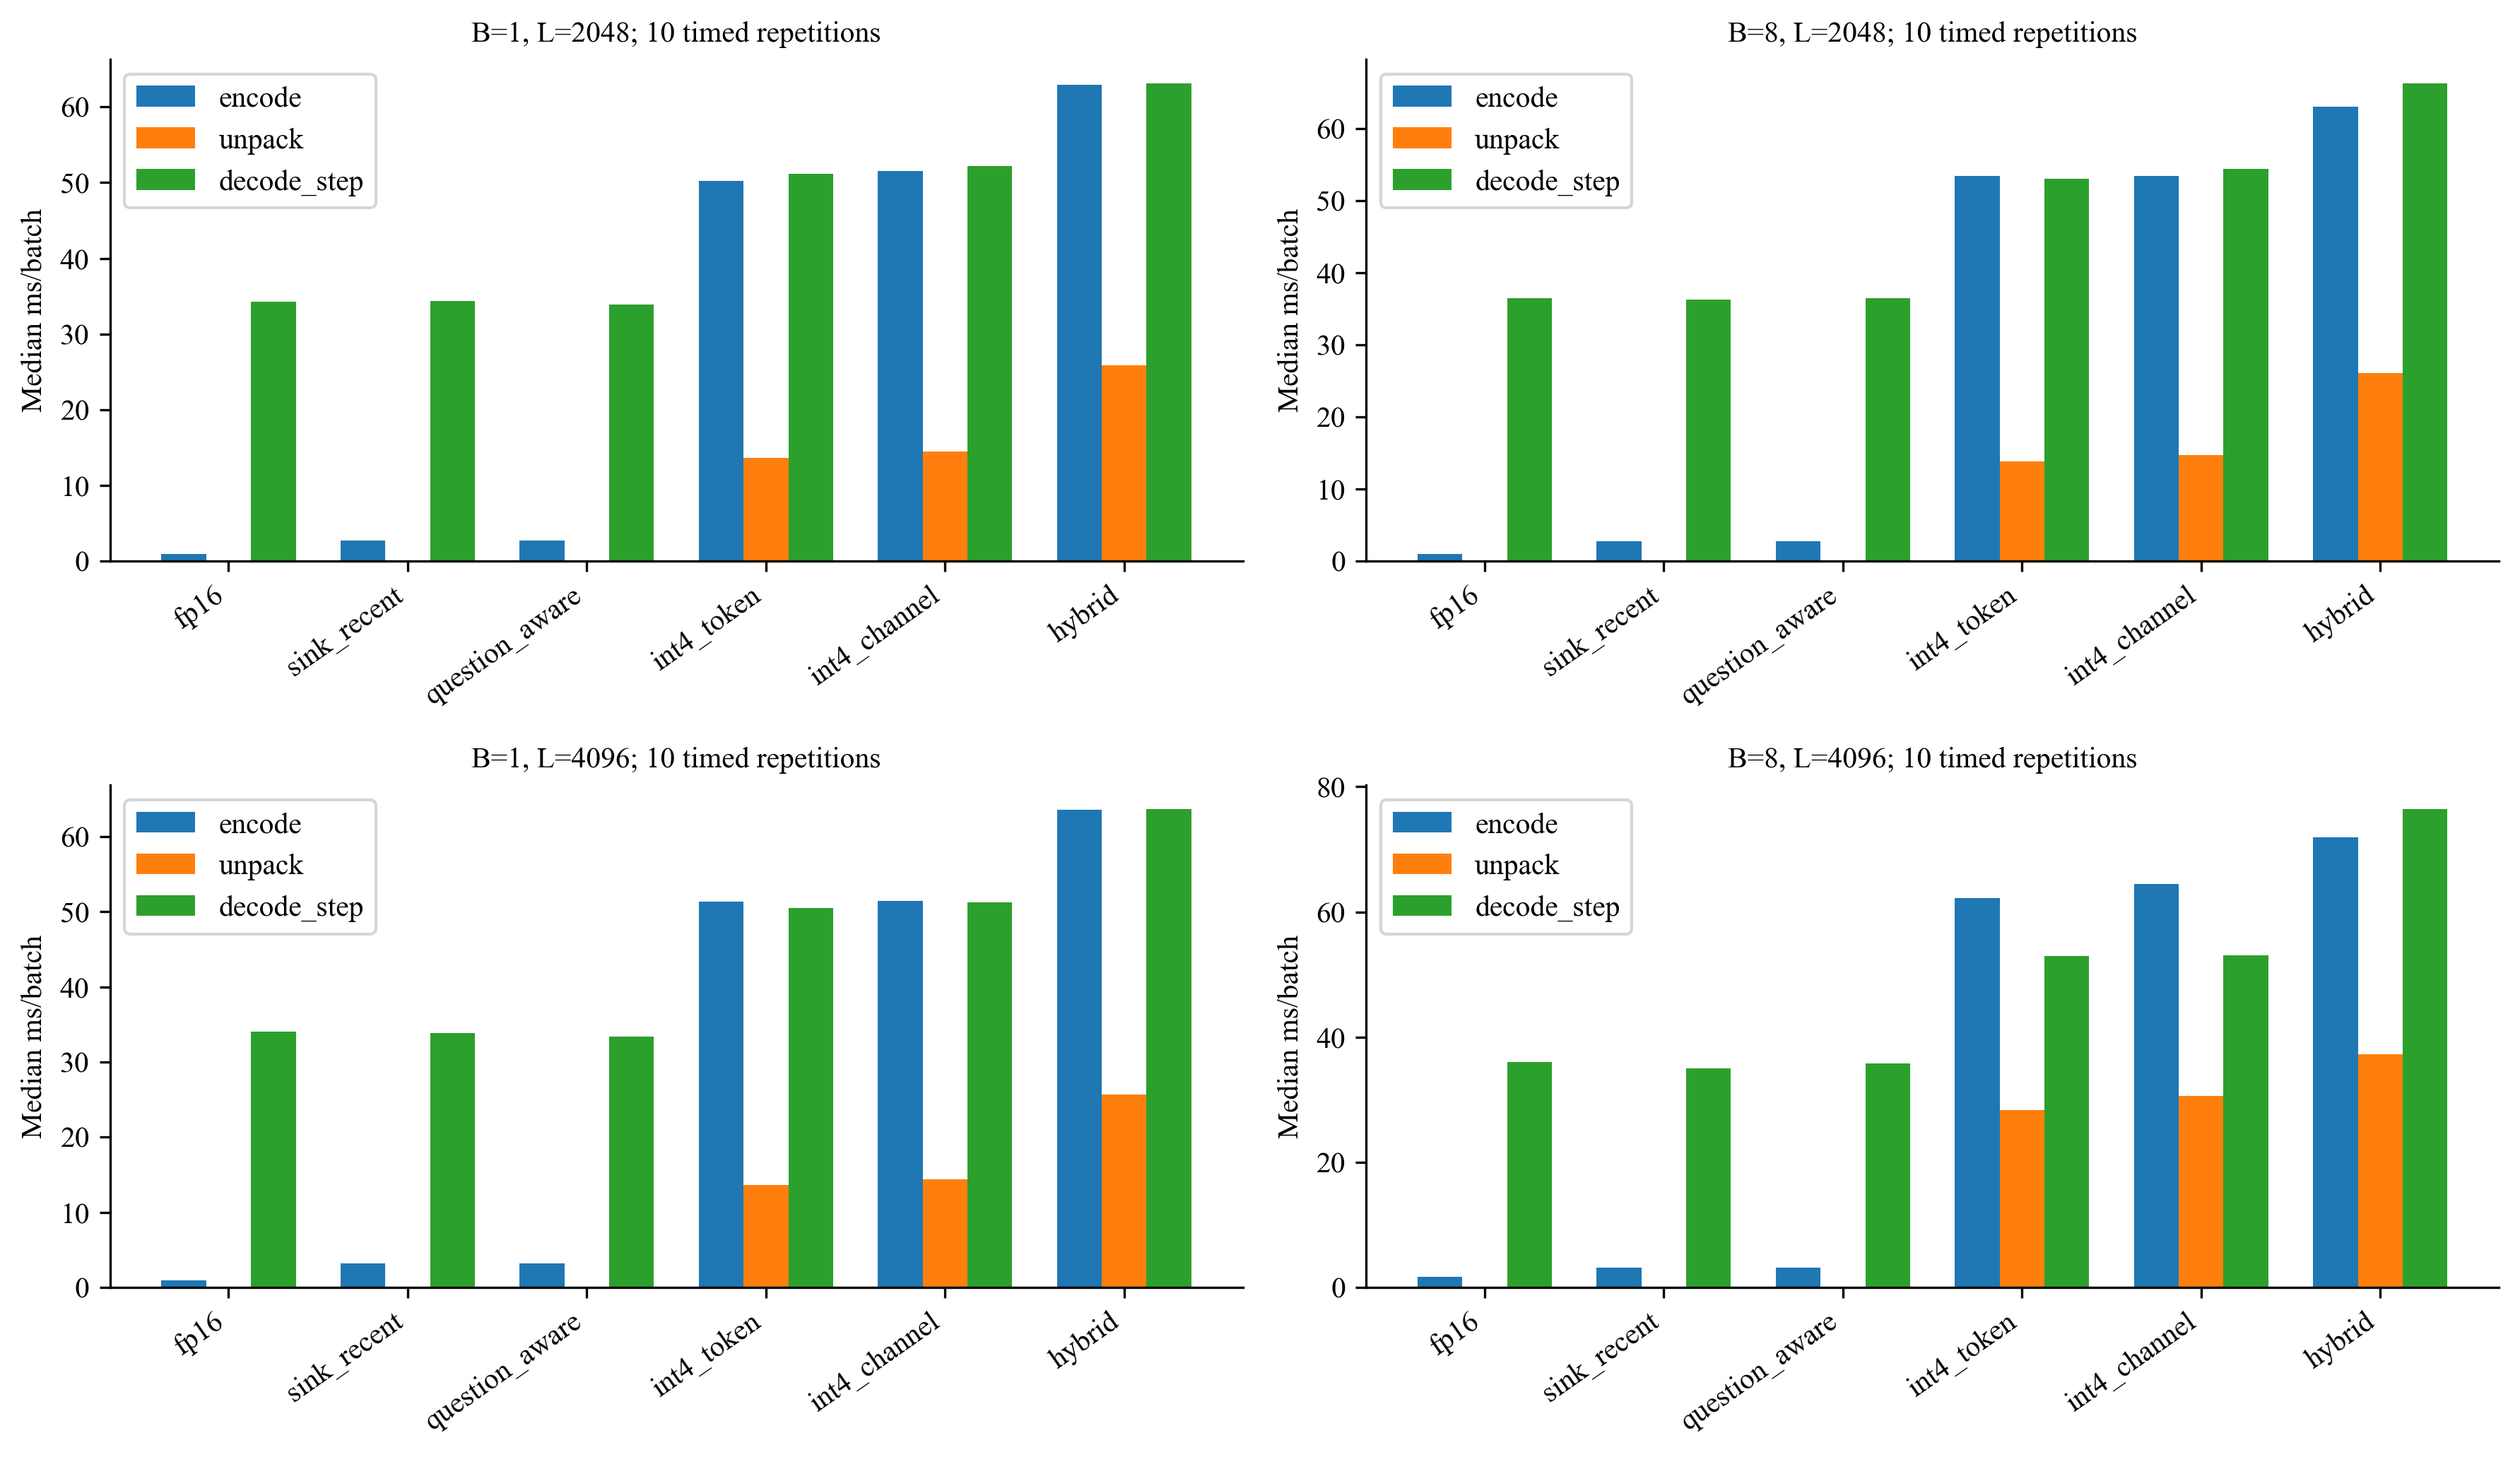

figures/rq4_resources_and_overheads.png


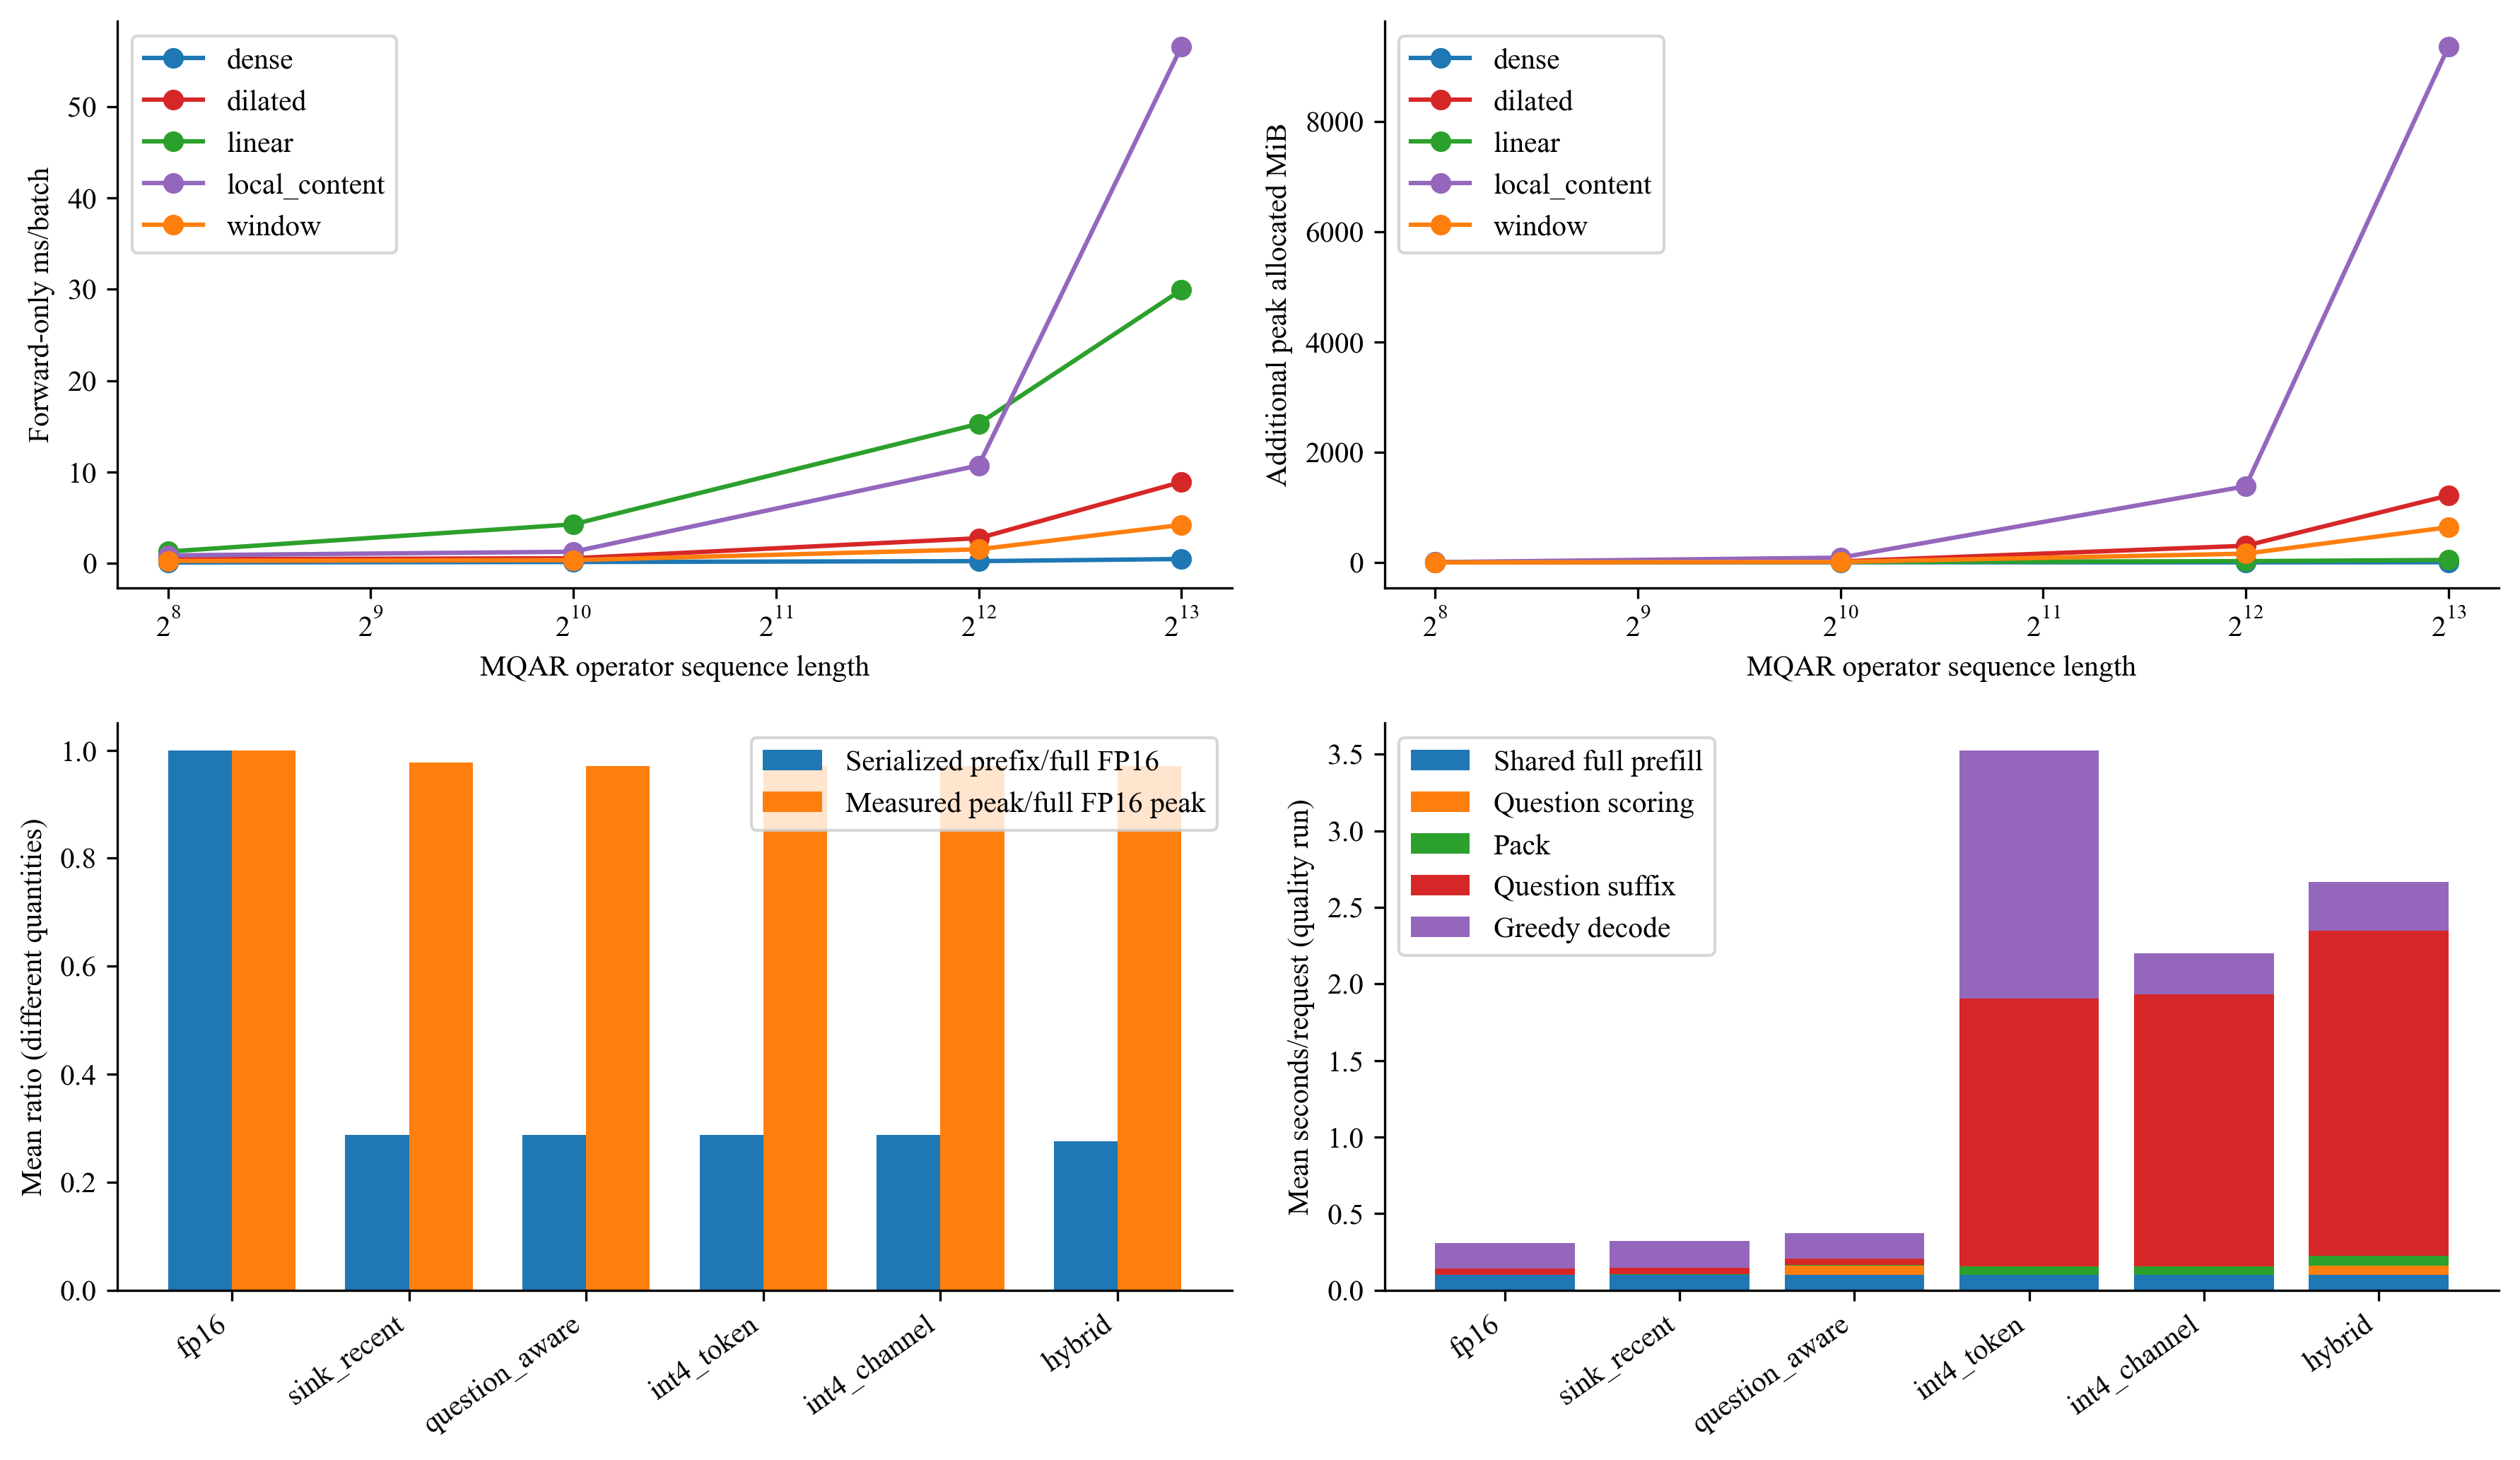

In [35]:
display_question(session, 'rq4', 'figures')


In [36]:
display_question(session, 'rq4', 'metrics')


metrics/kv/model_geometry.json


{'layers': 28,
 'kv_heads': 2,
 'query_heads': 12,
 'head_dimension': 128,
 'parameters': 1543714304,
 'model': 'Qwen/Qwen2.5-1.5B-Instruct',
 'revision': '989aa7980e4cf806f80c7fef2b1adb7bc71aa306',
 'attention_backend': 'sdpa',
 'eos_token_ids': [151645, 151643],
 'sdpa_observed_prefill_operators': ['aten::_flash_attention_forward',
  'aten::_scaled_dot_product_flash_attention',
  'aten::scaled_dot_product_attention'],
 'sdpa_observed_decode_operators': ['aten::_flash_attention_forward',
  'aten::_scaled_dot_product_flash_attention',
  'aten::scaled_dot_product_attention']}

### Fixed aligned retrieval examples

The fixed six prompt IDs retain every policy’s response, gold span and FP16-selection mask. These examples are selected by supplied case order, never by whether a method won.


In [37]:
from Task_2.common.artifacts import read_json
examples = read_json(session.paths["results"] / "examples/kv_aligned.json")
display(pd.DataFrame([{key: row.get(key) for key in ["id", "method", "status", "correct", "evidence_retention_fraction"]} |
                      {"response": row["response"]["text"]} for row in examples]))
display({"id": examples[0]["id"], "gold_evidence_span": examples[0]["evidence_text"]})
print("Full unchanged prompts, evidence coordinates and token-selection masks: examples/kv_aligned.json")


,id,method,status,correct,evidence_retention_fraction,response
0,KV-2048-end-0-00,fp16,complete,True,1.0,38757
1,KV-2048-end-0-00,hybrid,complete,True,1.0,38757
2,KV-2048-end-0-00,int4_channel,complete,True,1.0,38757
3,KV-2048-end-0-00,int4_token,complete,False,1.0,airport 7 airport river airport river river...
4,KV-2048-end-0-00,question_aware,complete,True,1.0,38757
5,KV-2048-end-0-00,sink_recent,complete,True,1.0,38757
6,KV-2048-middle-0-00,fp16,complete,True,1.0,32056
7,KV-2048-middle-0-00,hybrid,complete,True,1.0,32056
8,KV-2048-middle-0-00,int4_channel,complete,True,1.0,32056
9,KV-2048-middle-0-00,int4_token,complete,False,1.0,warehouse warehouse warehouse river wareho...


{'id': 'KV-2048-end-0-00',
 'gold_evidence_span': 'IMPORTANT RECORD: access code for CASE-2048-END-0-00 is 38757.'}

Full unchanged prompts, evidence coordinates and token-selection masks: examples/kv_aligned.json


## Completion and download

Validate all registered artifacts, counts and saved predictions before declaring completion. Download `MyDrive/ATML_PA4/PA_4/Task_2/results/` into local `Task_2/results/`, preserving the run folder. Keep large checkpoints on Drive if only replay is needed. Run this same notebook locally in ATML; missing evidence raises an error and never launches training.


In [38]:
display(session.finish())


Validating Task 2 saved evidence: 10847 registered files...


Verified 42 training conditions and their saved query annotations.


Verified final MQAR predictions: 9/54 variants.


Verified final MQAR predictions: 18/54 variants.


Verified final MQAR predictions: 27/54 variants.


Verified final MQAR predictions: 36/54 variants.


Verified final MQAR predictions: 45/54 variants.


Verified final MQAR predictions: 54/54 variants.


{'status': 'complete', 'source': 'Google Colab', 'run_id': 'task2_seed6304_v1'}